# Proyecto de grado MIAD

Presentado por:
- Laura Marcela Ramirez Casallas
- Kevin Alejandro Caicedo Rodriguez
- Jhon Jairo Meneses Prieto
- Jeferson Andrés Gutiérrez Gutiérrez

# Instalación Librerías y obtención data

In [ ]:
import pandas as pd
import requests
import time
import seaborn as sns

import matplotlib.pyplot as plt

In [ ]:
DOMINIO = "https://www.datos.gov.co"
ID = "7y2j-43cv"
API = f"{DOMINIO}/resource/{ID}.json"

meta = requests.get(
    f"{DOMINIO}/api/views/{ID}.json",
    timeout=60
).json()

columnas = [
    {
        "campo": c["fieldName"],
        "nombre": c.get("name"),
        "tipo": c.get("dataTypeName")
    }
    for c in meta["columns"]
    if c.get("fieldName") and not c["fieldName"].startswith(":")
]

display(pd.DataFrame(columnas))

,campo,nombre,tipo
0,pk,PK,text
1,matricula,MATRICULA,text
2,fecha_radica_texto,FECHA_RADICA_TEXTO,text
3,fecha_apertura_texto,FECHA_APERTURA_TEXTO,text
4,year_radica,YEAR_RADICA,text
5,orip,ORIP,text
6,divipola,DIVIPOLA,text
7,departamento,DEPARTAMENTO,text
8,municipio,MUNICIPIO,text
9,tipo_predio_zona,TIPO_PREDIO_ZONA,text


# Calidad de los datos

## Muestra Inicial

In [ ]:
def consultar(params):
    respuesta = requests.get(API, params=params, timeout=120)
    respuesta.raise_for_status()
    return respuesta.json()

In [ ]:
total = consultar({"$select": "count(*) as total"})[0]["total"]
print("Total de registros:", total)

muestra = consultar({"$limit": 5})
display(pd.DataFrame(muestra))

Total de registros: 30903248


,pk,matricula,fecha_radica_texto,fecha_apertura_texto,year_radica,orip,divipola,departamento,municipio,tipo_predio_zona,...,num_anotacion,dinamica_2024,cod_natujur,nombre_natujur,documento_justificativo,count_a,count_de,predios_nuevos,tiene_valor,tiene_mas_de_un_valor
0,05001-001-000013-00014-00313-2018,001-13,2018-02-05 00:00:00,1973-01-11 00:00:00,2018,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,14,0,313,CONSTITUCIÓN DE FIDEICOMISO CIVIL,01-ESCRITURA 3321 DE 22-12-2017; NOTARIA SEGUN...,2,1,0,0,0
1,05001-001-000014-00015-00313-2018,001-14,2018-02-05 00:00:00,1973-01-11 00:00:00,2018,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,15,0,313,CONSTITUCIÓN DE FIDEICOMISO CIVIL,01-ESCRITURA 3321 DE 22-12-2017; NOTARIA SEGUN...,2,1,0,0,0
2,05001-001-000023-00007-00109-2020,001-23,2020-12-02 00:00:00,1973-01-10 00:00:00,2020,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,7,1,109,ADJUDICACIÓN EN SUCESION,01-ESCRITURA 3322 DE 30-10-2020; NOTARIA OCTAV...,5,1,0,0,0
3,05001-001-000065-00013-00317-2015,001-65,2015-12-16 00:00:00,1973-01-10 00:00:00,2015,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,13,1,317,CONSTITUCIÓN REGLAMENTO DE PROPIEDAD HORIZONTAL,01-ESCRITURA 8145 DE 04-12-2015; NOTARIA DIECI...,0,1,0,0,0
4,05001-001-000067-00014-00109-2016,001-67,2016-03-29 00:00:00,1973-01-11 00:00:00,2016,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,14,1,109,ADJUDICACIÓN EN SUCESION,01-ESCRITURA 1266 DE 10-03-2016; NOTARIA DIECI...,1,1,0,0,0


## Completitud

In [ ]:
resultados = []

for c in columnas:
    campo = c["campo"]
    condicion = f"{campo} IS NULL"

    # Para columnas de texto, cuenta también cadenas vacías
    if c["tipo"] == "text":
        condicion = f"({campo} IS NULL OR {campo} = '')"

    conteo = consultar({
        "$select": "count(*) as n",
        "$where": condicion
    })[0]["n"]

    resultados.append({
        "campo": campo,
        "tipo": c["tipo"],
        "faltantes_o_vacios": int(conteo),
        "porcentaje": round(100 * int(conteo) / int(total), 2)
    })

perfil_faltantes = (
    pd.DataFrame(resultados)
      .sort_values("porcentaje", ascending=False)
)

display(perfil_faltantes)

,campo,tipo,faltantes_o_vacios,porcentaje
18,numero_catastral_antiguo,text,30903248,100.00
17,numero_catastral,text,30903248,100.00
13,folios_derivados,text,30601558,99.02
3,fecha_apertura_texto,text,14368727,46.50
12,estado_folio,text,13579939,43.94
25,valor,number,12683596,41.04
19,documento_justificativo,text,7748,0.03
2,fecha_radica_texto,text,1,0.00
1,matricula,text,0,0.00
0,pk,text,0,0.00


### Conclusión
- las variables como numero_catastral_antiguo y numero_catastral muestra 100% de valores faltantes, por lo que no va a aportar nada a la data
- folios_deivados representa un 99.02% de valores faltantes solo 0.98% presenta valores por lo cual no es tan representativo esta data
- También podemos ver algunos campos que también representa un buen procentaje de valores faltantes como fecha_apertura_texto con 46.5%, estado_folio con 43.94% y por último valor con 41.04%

## Consistencia

In [ ]:
diccionario = [
    {
        "campo": c.get("fieldName"),
        "nombre": c.get("name"),
        "tipo": c.get("dataTypeName"),
        "descripcion": c.get("description")
    }
    for c in meta["columns"]
    if c.get("fieldName") and not c["fieldName"].startswith(":")
]

df_diccionario = pd.DataFrame(diccionario)

display(
    df_diccionario.style
    .set_properties(
        subset=["descripcion"],
        **{
            "white-space": "normal",
            "word-break": "break-word",
            "min-width": "400px",
            "max-width": "700px",
            "text-align": "left",
            "vertical-align": "top"
        }
    )
    .set_properties(**{
        "text-align": "left",
        "vertical-align": "top"
    })
)



,campo,nombre,tipo,descripcion
0,pk,PK,text,"Es el número único de cada transacción, que permite distinguir una transacción de otra."
1,matricula,MATRICULA,text,Corresponde con el número de folio de la matrícula inmobiliaria creado por la oficina de registro de instrumentos públicos - ORIP. Se compone de dos partes: los 3 primeros dígitos coinciden con el código de la ORIP y el resto es el número de cada folio.
2,fecha_radica_texto,FECHA_RADICA_TEXTO,text,Corresponde con la fecha de radicación del trámite que deriva en una nueva anotación en el folio de matrícula correspondiente.
3,fecha_apertura_texto,FECHA_APERTURA_TEXTO,text,"Corresponde con la fecha de creación del folio. Aunque en términos generales la fecha de apertura debe ser inferior a la fecha de radicación no siempre es así, dado que hay trámites que se radican a finales de año y se materializan en el año siguiente, otra explicación puede ser lo relacionado con el tema de sentencias judiciales o correcciones que otorguen firmeza posterior a la fecha de radicación."
4,year_radica,YEAR_RADICA,text,Año en el que se contabiliza la transacción.
5,orip,ORIP,text,"Código de la oficina de registro de instrumentos públicos. Colombia tiene 198 oficinas de registro, cada una tiene una jurisdicción específica sobre algunos municipios, en términos generales es estable, pero en algunos casos por temas de facilitar el acceso a los usuarios se modifica, por lo cual, si encuentra variaciones a lo largo del tiempo, no se trata de errores."
6,divipola,DIVIPOLA,text,"Es la codificación geográfica que permite identificar las divisiones político-administrativas de Colombia de manera única. Se compone de dos (2) dígitos que identifican cada departamento, iniciando con el 05 para el departamento de Antioquia; tres (3) dígitos que identifican cada municipio, a partir del 001 para la capital del departamento."
7,departamento,DEPARTAMENTO,text,Nombre del departamento en el que se ubica el predio objeto de la transacción
8,municipio,MUNICIPIO,text,Nombre del municipio en el que se ubica el predio objeto de la transacción
9,tipo_predio_zona,TIPO_PREDIO_ZONA,text,"Corresponde a la zona en la que se ubica el predio objeto de la transacción. Es el resultado de un proceso de depuración, que se enriquece a partir de la DIRECCION del predio. Puede ser URBANO, en el caso en que el predio se encuentra en el área comprendida dentro del perímetro urbano y demás agrupaciones de predios con características urbanas denominadas corregimientos, debidamente aprobado por la autoridad, RURAL en caso en que se identifique que el predio objeto de transacción se encuentre ubicado fuera de alguno de los perímetros urbanos ya sea de la cabecera municipal, o de los corregimientos. Son Terrenos no aptos para el uso urbano por razones de oportunidad o por su destinación a usos agrícolas, ganaderos, forestales, de explotación de recursos naturales y actividades análogas. SIN INFRORMACIÓN, en caso en que, no sea posible reconocer el predio como URBANO o RURAL. El carácter de este campo NO es normativo y por ende en algunos casos puede NO corresponder con los instrumentos de ordenamiento territorial, se recomienda cotejar este dato con el contenido en el número predial en caso de estar disponible, sin decir con esto que uno reemplace al otro o que uno sea más verídico que el otro."


In [ ]:
campos_revisar = [
    c["campo"] for c in columnas
    if c["tipo"] in ["text", "number", "calendar", "money"]
]

for campo in campos_revisar:
    condicion = f"{campo} IS NOT NULL"

    datos = consultar({
        "$select": campo,
        "$where": condicion,
        "$limit": 20
    })

    valores = [fila.get(campo) for fila in datos]
    print(f"\n{campo}: {valores}")



pk: ['05001-001-000013-00014-00313-2018', '05001-001-000014-00015-00313-2018', '05001-001-000023-00007-00109-2020', '05001-001-000065-00013-00317-2015', '05001-001-000067-00014-00109-2016', '05002-002-006532-00011-00125-2016', '05002-002-006532-00012-00125-2016', '05002-002-008032-00012-00125-2021', '05002-002-008032-00013-00125-2022', '05030-033-017552-00003-00920-2017', '05030-033-017552-00004-00901-2017', '05030-033-017552-00005-00901-2017', '05030-033-017552-00006-00901-2017', '05030-033-017553-00003-00920-2017', '05030-033-017553-00004-00125-2017', '05030-033-018439-00002-00125-2022', '05030-033-018440-00001-00924-2019', '05030-033-018440-00002-00125-2022', '05030-033-018441-00001-00924-2019', '05030-033-018441-00002-00125-2022']

matricula: ['001-13', '001-14', '001-23', '001-65', '001-67', '002-6532', '002-6532', '002-8032', '002-8032', '033-17552', '033-17552', '033-17552', '033-17552', '033-17553', '033-17553', '033-18439', '033-18440', '033-18440', '033-18441', '033-18441']


In [ ]:
resultado = consultar({
    "$select": "count(distinct orip) as orip_unicos"
})

print("Valores únicos de ORIP:", resultado[0]["orip_unicos"])

Valores únicos de ORIP: 196


Se valida la cantidad de oficinas registradas en la base de datos para ORIP porque indica que Colombia tiene 198 oficinas y en este caso y en esta base vemos 196, por lo que es coherente y válido ese valor

In [ ]:
resultado = consultar({
    "$select": "distinct tipo_predio_zona as tipo_predio_zona_unicos"
})

valores_unicos = [
    fila["tipo_predio_zona_unicos"]
    for fila in resultado
]

print("Cantidad de valores únicos:", len(valores_unicos))
print(valores_unicos)

Cantidad de valores únicos: 3
['RURAL', 'SIN INFORMACION', 'URBANO']


Descripción indica que debe tener solo 3 valores RURAL, SIN INFORMACION y URBANO, y al hacer la búsqueda efectivamente así es.

In [ ]:
resultado = consultar({
    "$select": "distinct estado_folio as estado_folio_unico",
})

valores_unicos = sorted({
    fila.get("estado_folio_unico")
    for fila in resultado
}, key=lambda x: str(x))

print("Cantidad de valores únicos:", len(valores_unicos))
print(valores_unicos)


Cantidad de valores únicos: 4
['ACTIVO', 'CERRADO', 'CUSTODIA', None]


La descripción indicia que solo debe tener 3 valores "ACTIVO", "CERRADO", "CUSTODIA" así que está bien acorde a lo anterior y tener en cuenta que dice None es decir valores faltantes.

In [ ]:
resultado = consultar({
    "$select": "distinct dinamica_2024 as dinamica_2024_unico",
})

valores_unicos = sorted({
    fila.get("dinamica_2024_unico")
    for fila in resultado
}, key=lambda x: str(x))

print("Cantidad de valores únicos:", len(valores_unicos))
print(valores_unicos)


Cantidad de valores únicos: 2
['0', '1']


La descripción indica que el campo de dinamica_2024 debe tener solamente 2 valores 0 o 1

In [ ]:
resultado = consultar({
    "$select": "distinct predios_nuevos as predios_nuevo_unico",
})

valores_unicos = sorted({
    fila.get("predios_nuevo_unico")
    for fila in resultado
}, key=lambda x: str(x))

print("Cantidad de valores únicos:", len(valores_unicos))
print(valores_unicos)

Cantidad de valores únicos: 2
['0', '1']


La descripción indica que el campo de predios_nuevos debe tener solamente 2 valores 0 o 1

In [ ]:
resultado = consultar({
    "$select": "distinct tiene_valor as tiene_valor_unico",
})

valores_unicos = sorted({
    fila.get("tiene_valor_unico")
    for fila in resultado
}, key=lambda x: str(x))

print("Cantidad de valores únicos:", len(valores_unicos))
print(valores_unicos)

Cantidad de valores únicos: 2
['0', '1']


La descripción indica que el campo de tiene_valor debe tener solamente 2 valores 0 o 1

In [ ]:
resultado = consultar({
    "$select": "distinct tiene_mas_de_un_valor as tiene_mas_de_un_valor_unico",
})

valores_unicos = sorted({
    fila.get("tiene_mas_de_un_valor_unico")
    for fila in resultado
}, key=lambda x: str(x))

print("Cantidad de valores únicos:", len(valores_unicos))
print(valores_unicos)

Cantidad de valores únicos: 2
['0', '1']


La descripción indica que el campo de tiene_mas_de_un_valor debe tener solamente 2 valores 0 o 1

In [ ]:
# Registros marcados como que tienen valor, pero cuyo valor registrado es 0
resultado = consultar({
    "$select": "count(*) as cantidad",
    "$where": "tiene_valor = 1 AND valor = 0"
})

cantidad_cero = int(resultado[0]["cantidad"])

# Total de registros donde tiene_valor = 1
resultado_total = consultar({
    "$select": "count(*) as cantidad",
    "$where": "tiene_valor = 1"
})

total_con_valor = int(resultado_total[0]["cantidad"])

porcentaje = (
    100 * cantidad_cero / total_con_valor
    if total_con_valor > 0
    else 0
)

print("Registros con tiene_valor = 1 y valor = 0:", f"{cantidad_cero:,}")
print("Total de registros con tiene_valor = 1:", f"{total_con_valor:,}")
print("Porcentaje dentro de tiene_valor = 1:", f"{porcentaje:.2f}%")

Registros con tiene_valor = 1 y valor = 0: 10,707,398
Total de registros con tiene_valor = 1: 18,219,652
Porcentaje dentro de tiene_valor = 1: 58.77%


In [ ]:
# Total de registros con pk informado
total_pk = consultar({
    "$select": "count(pk) as cantidad"
})[0]["cantidad"]

# Cantidad de valores distintos de pk
pk_distintos = consultar({
    "$select": "count(distinct pk) as cantidad"
})[0]["cantidad"]

total_pk = int(total_pk)
pk_distintos = int(pk_distintos)

# Diferencia: número de registros que exceden la primera aparición de cada pk
repeticiones_excedentes = total_pk - pk_distintos

print("Registros con pk informado:", f"{total_pk:,}")
print("Valores únicos de pk:", f"{pk_distintos:,}")
print("Repeticiones excedentes:", f"{repeticiones_excedentes:,}")

if repeticiones_excedentes == 0:
    print("No se detectan valores repetidos en pk.")
else:
    print("Hay registros con pk repetido; conviene inspeccionarlos antes de decidir qué hacer.")


Registros con pk informado: 30,903,248
Valores únicos de pk: 30,903,248
Repeticiones excedentes: 0
No se detectan valores repetidos en pk.


### Conclusión
| Variable | Tipo de dato | Incosistencia |
|----------|--------------|-------------|
| matricula | String | tiene valores duplicados y repetidos por lo que es importante validar esto |
| fecha_radica_texto | String | primero es de tipo string este campo y no de fecha y segundo es importante normalizar las fechas porque hay unas con este valor 2016-03-29 00:00:00 y otras con 29/09/2016 que me permita ver correctamente una serie de tiempo |
| fecha_apertura_texto | String | Es de tipo string por lo que es necesario validar si convertirlo a tipo fecha que me permita ver correctamente una serie de tiempo.  |
| year_radica | String | El formato está en String pero es importante que estén en Entero, para ver las tendencias, hacer cruces con otra información, evolución |
| tipo_predio_zona | String | tiene 2 datos normales como son "URBANO" y "RURAL" pero tiene un 3er dato que es "SIN INFORMACIÓN" lo cual podría ser un dato faltante ya que no está identificado ese lugar |
| folios_derivados | String | tiene 2 datos normales como son "URBANO" y "RURAL" pero tiene un 3er dato que es "SIN INFORMACIÓN" lo cual podría ser un dato faltante ya que no está identificado ese lugar |
| numero_catastral | String | No tiene valores está vacío |
| numero_catastral_antiguo | String | No tiene valores está vacío |
| tiene_valor y valor | Number | tiene valor es igual a 1 pero valor no tiene es una incosistencia |


## Claridad

In [ ]:
campos_numericos = [
    c["campo"]
    for c in columnas
    if c["tipo"] == "number"
]

print(campos_numericos)

['num_anotacion', 'dinamica_2024', 'cod_natujur', 'count_a', 'count_de', 'predios_nuevos', 'tiene_valor', 'tiene_mas_de_un_valor', 'valor']


In [ ]:
resultados = []

for campo in campos_numericos:
    datos = consultar({
        "$select": (
            f"count({campo}) as n, "
            f"avg({campo}) as media, "
            f"min({campo}) as minimo, "
            f"max({campo}) as maximo"
        )
    })[0]

    resultados.append({
        "campo": campo,
        "n": int(datos["n"]),
        "media": datos["media"],
        "minimo": datos["minimo"],
        "maximo": datos["maximo"]
    })

tabla_basica = pd.DataFrame(resultados)
display(tabla_basica)


,campo,n,media,minimo,maximo
0,num_anotacion,30903248,11.2872680567427734,1,30088
1,dinamica_2024,30903248,0.56307495574575203228,0,1
2,cod_natujur,30903248,456.4104800246239489,100,4010
3,count_a,30903248,1.2306140765527300,0,10791
4,count_de,30903248,1.0104738181565899,0,6744
5,predios_nuevos,30903248,0.09410211509159166700,0,1
6,tiene_valor,30903248,0.58957077909739455218,0,1
7,tiene_mas_de_un_valor,30903248,0.000033297470867787101213,0,1
8,valor,18219652,583604755.69871676,0.0,3789999940000000


In [ ]:
modas = []

for campo in campos_numericos:
    datos = consultar({
        "$select": f"{campo}, count(*) as frecuencia",
        "$where": f"{campo} IS NOT NULL",
        "$group": campo,
        "$order": "frecuencia DESC",
        "$limit": 1
    })

    modas.append({
        "campo": campo,
        "moda": datos[0].get(campo) if datos else None,
        "frecuencia_moda": int(datos[0]["frecuencia"]) if datos else 0
    })

tabla_modas = pd.DataFrame(modas)
display(tabla_modas)


,campo,moda,frecuencia_moda
0,num_anotacion,2,3381204
1,dinamica_2024,1,17400845
2,cod_natujur,125,5424769
3,count_a,1,20764843
4,count_de,1,19926568
5,predios_nuevos,0,27995187
6,tiene_valor,1,18219652
7,tiene_mas_de_un_valor,0,30902219
8,valor,0.0,10707398


In [ ]:
resultados_mediana = []

for campo in campos_numericos:
    resultado = consultar({
        "$select": f"median({campo}) as mediana"
    })[0]

    resultados_mediana.append({
        "variable": campo,
        "mediana": resultado.get("mediana")
    })

tabla_medianas = pd.DataFrame(resultados_mediana)
display(tabla_medianas)

,variable,mediana
0,num_anotacion,6
1,dinamica_2024,1
2,cod_natujur,317
3,count_a,1
4,count_de,1
5,predios_nuevos,0
6,tiene_valor,1
7,tiene_mas_de_un_valor,0
8,valor,0


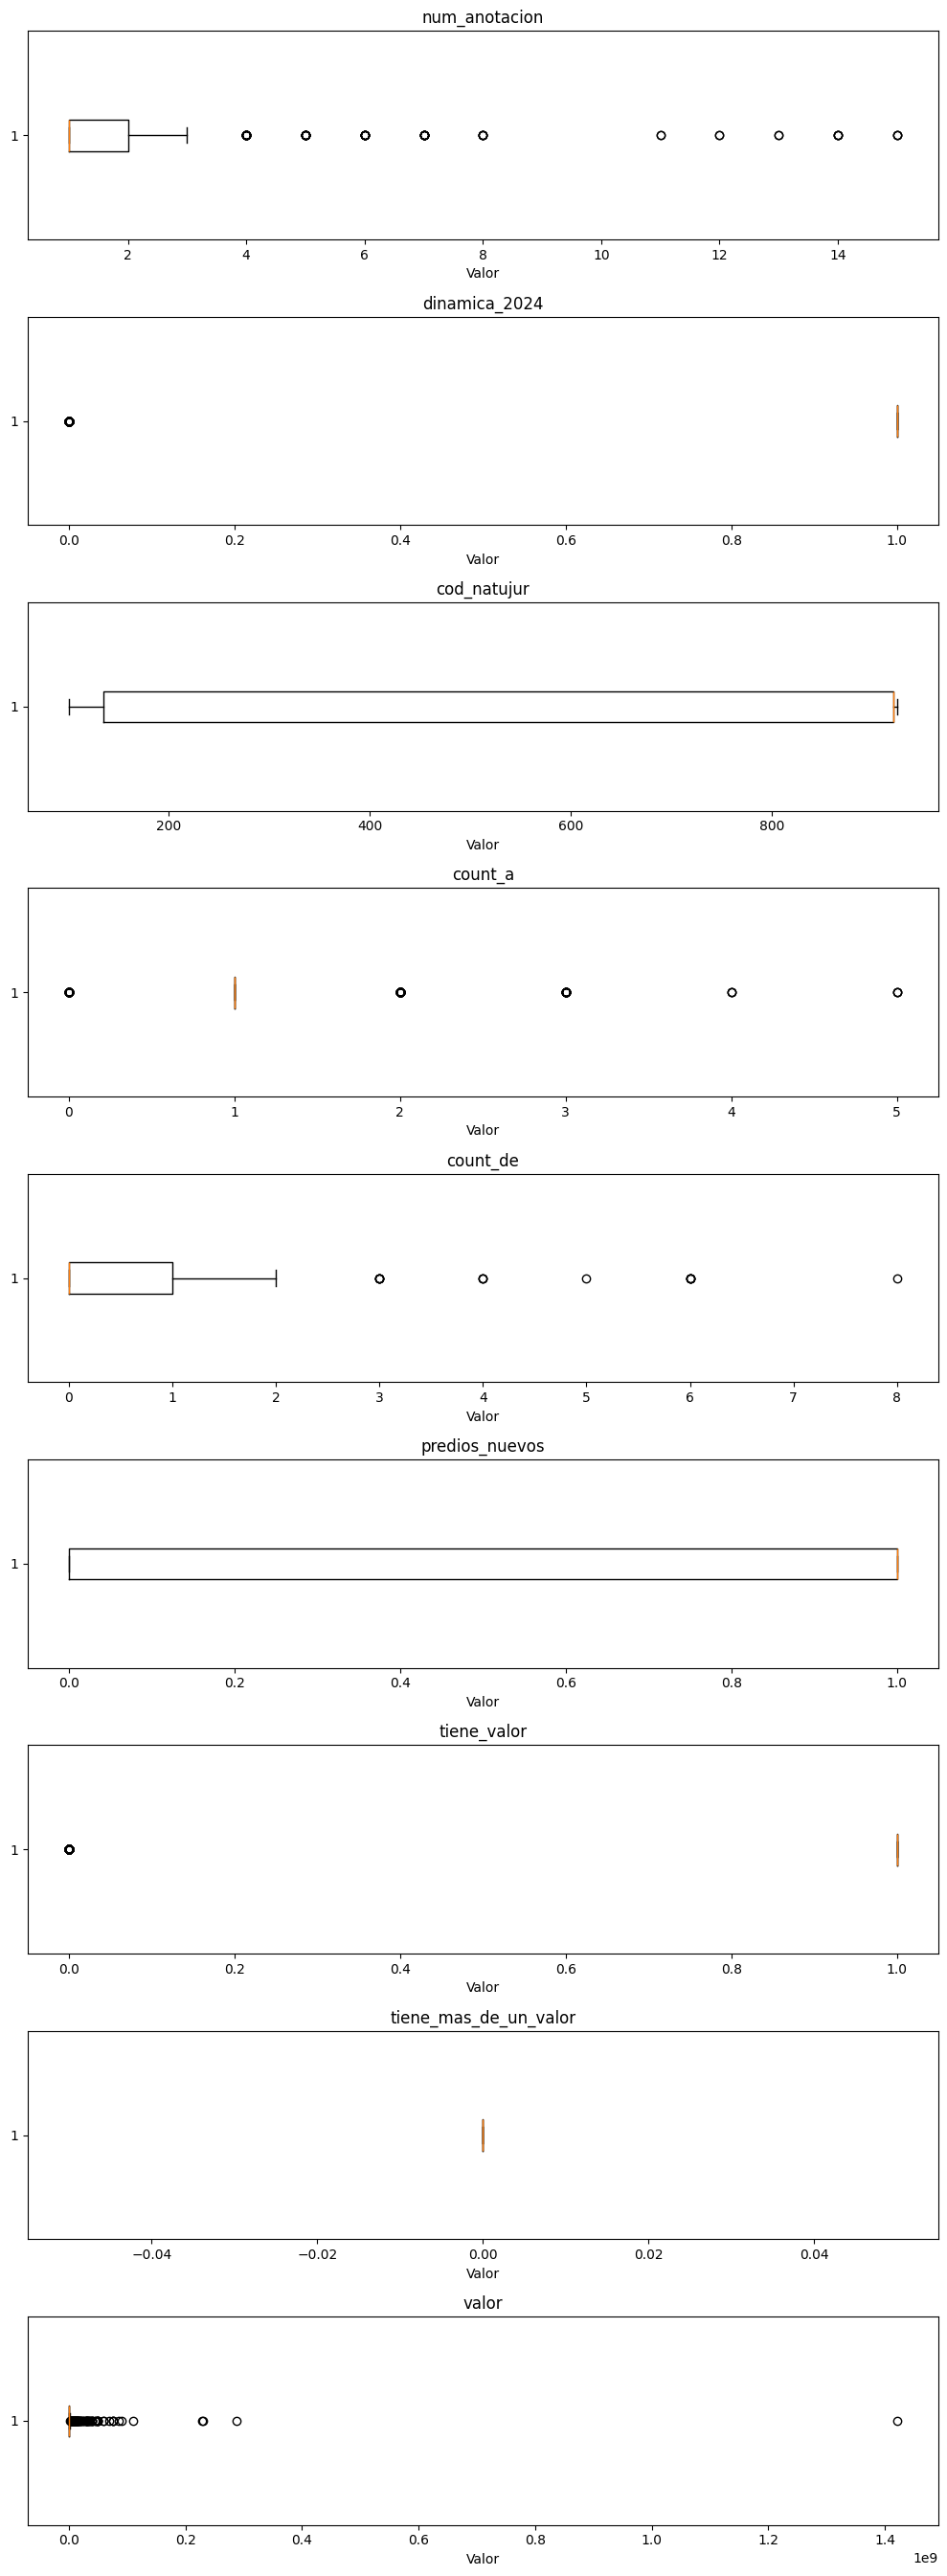

In [ ]:
campos_numericos = [
    c["campo"] for c in columnas
    if c["tipo"] == "number"
]

filas = consultar({
    "$select": ", ".join(campos_numericos)
})

df_box = pd.DataFrame(filas)

for campo in campos_numericos:
    df_box[campo] = pd.to_numeric(df_box[campo], errors="coerce")

fig, ejes = plt.subplots(
    len(campos_numericos), 1,
    figsize=(10, 3 * len(campos_numericos)),
    squeeze=False
)

for i, campo in enumerate(campos_numericos):
    valores = df_box[campo].dropna()
    ejes[i, 0].boxplot(valores, vert=False)
    ejes[i, 0].set_title(campo)
    ejes[i, 0].set_xlabel("Valor")

plt.tight_layout()
plt.show()


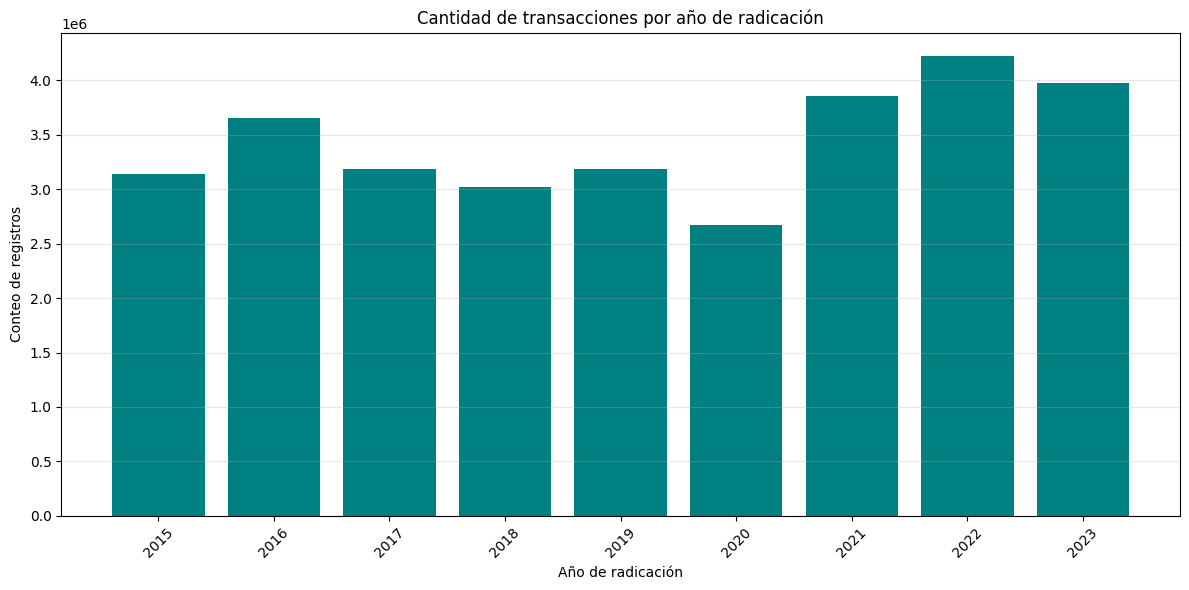

In [ ]:
# Agrupa todos los registros por año de radicación
resultado = consultar({
    "$select": "year_radica, count(*) as conteo",
    "$group": "year_radica",
    "$order": "year_radica"
})

# Convierte el resultado en una tabla
df_anios = pd.DataFrame(resultado)
df_anios["conteo"] = pd.to_numeric(df_anios["conteo"], errors="coerce")
df_anios["year_radica"] = df_anios["year_radica"].fillna("Sin dato")

# Ordena los años numéricamente y deja "Sin dato" al final
df_anios["orden"] = pd.to_numeric(df_anios["year_radica"], errors="coerce")
df_anios = df_anios.sort_values(
    "orden",
    na_position="last"
)

# Dibuja el gráfico
plt.figure(figsize=(12, 6))
plt.bar(df_anios["year_radica"].astype(str), df_anios["conteo"], color="teal")

plt.title("Cantidad de transacciones por año de radicación")
plt.xlabel("Año de radicación")
plt.ylabel("Conteo de registros")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

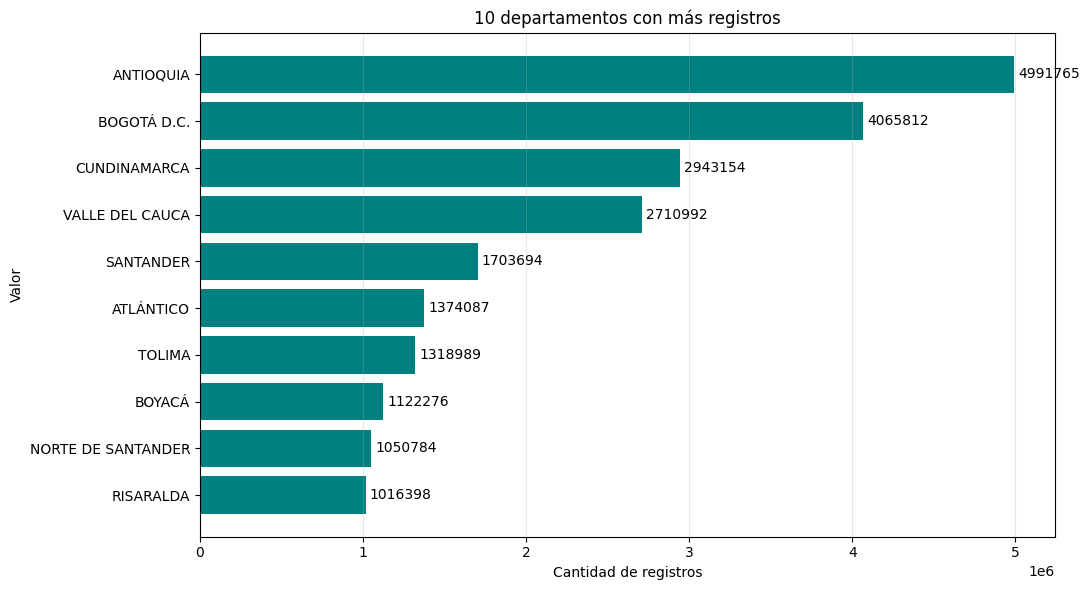

,etiqueta,cantidad
0,ANTIOQUIA,4991765
1,BOGOTÁ D.C.,4065812
2,CUNDINAMARCA,2943154
3,VALLE DEL CAUCA,2710992
4,SANTANDER,1703694
5,ATLÁNTICO,1374087
6,TOLIMA,1318989
7,BOYACÁ,1122276
8,NORTE DE SANTANDER,1050784
9,RISARALDA,1016398


In [ ]:
def graficar_top10(campos, etiqueta, titulo):
    """
    Agrupa todos los registros por los campos indicados,
    obtiene los 10 grupos más frecuentes y los grafica.
    """
    campos_select = ", ".join(campos)

    resultado = consultar({
        "$select": f"{campos_select}, count(*) as cantidad",
        "$where": " AND ".join([f"{campo} IS NOT NULL" for campo in campos]),
        "$group": campos_select,
        "$order": "cantidad DESC",
        "$limit": 10
    })

    df = pd.DataFrame(resultado)

    if df.empty:
        print(f"No se encontraron resultados para: {titulo}")
        return

    df["cantidad"] = pd.to_numeric(df["cantidad"], errors="coerce")

    # Crea una etiqueta por barra. En municipios incluye departamento y DIVIPOLA.
    if etiqueta == "municipio":
        df["etiqueta"] = (
            df["municipio"].astype(str)
            + " — " + df["departamento"].astype(str)
            + " (" + df["divipola"].astype(str) + ")"
        )
    else:
        df["etiqueta"] = df[etiqueta].astype(str)

    # El primer resultado, el más frecuente, queda arriba
    df = df.sort_values("cantidad", ascending=True)

    plt.figure(figsize=(11, 6))
    barras = plt.barh(df["etiqueta"], df["cantidad"], color="teal")

    plt.title(titulo)
    plt.xlabel("Cantidad de registros")
    plt.ylabel("Valor")
    plt.grid(axis="x", alpha=0.3)

    # Muestra el conteo al final de cada barra
    plt.bar_label(barras, fmt="%.0f", padding=3)

    plt.tight_layout()
    plt.show()

# 1. Departamentos con más registros
graficar_top10(
    campos=["departamento"],
    etiqueta="departamento",
    titulo="10 departamentos con más registros"
)


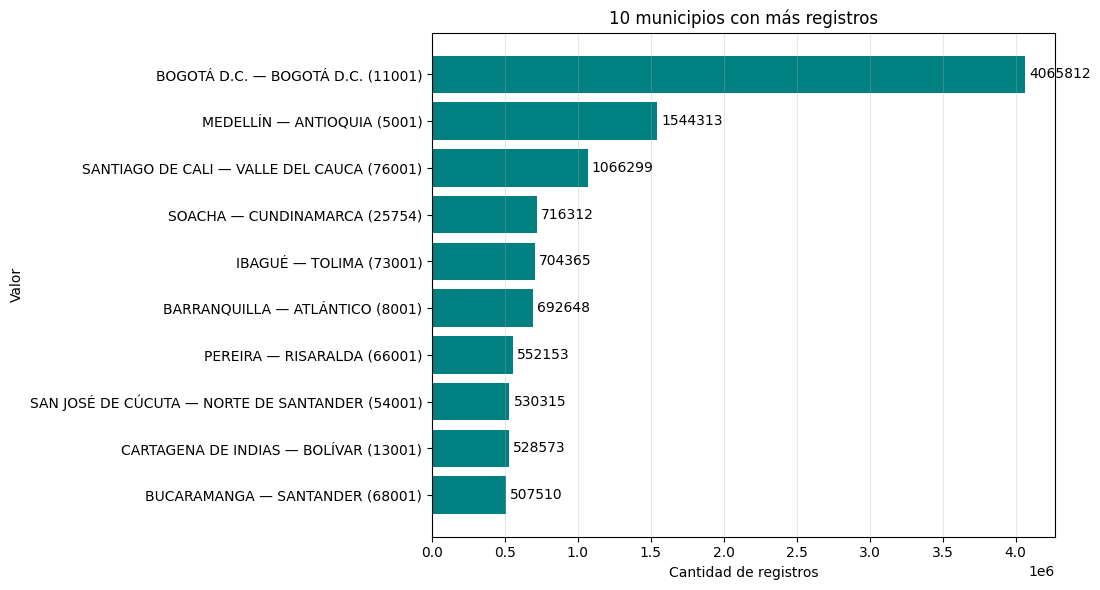

,etiqueta,cantidad
0,BOGOTÁ D.C. — BOGOTÁ D.C. (11001),4065812
1,MEDELLÍN — ANTIOQUIA (5001),1544313
2,SANTIAGO DE CALI — VALLE DEL CAUCA (76001),1066299
3,SOACHA — CUNDINAMARCA (25754),716312
4,IBAGUÉ — TOLIMA (73001),704365
5,BARRANQUILLA — ATLÁNTICO (8001),692648
6,PEREIRA — RISARALDA (66001),552153
7,SAN JOSÉ DE CÚCUTA — NORTE DE SANTANDER (54001),530315
8,CARTAGENA DE INDIAS — BOLÍVAR (13001),528573
9,BUCARAMANGA — SANTANDER (68001),507510


In [ ]:
# 2. Municipios con más registros
graficar_top10(
    campos=["divipola", "departamento", "municipio"],
    etiqueta="municipio",
    titulo="10 municipios con más registros"
)

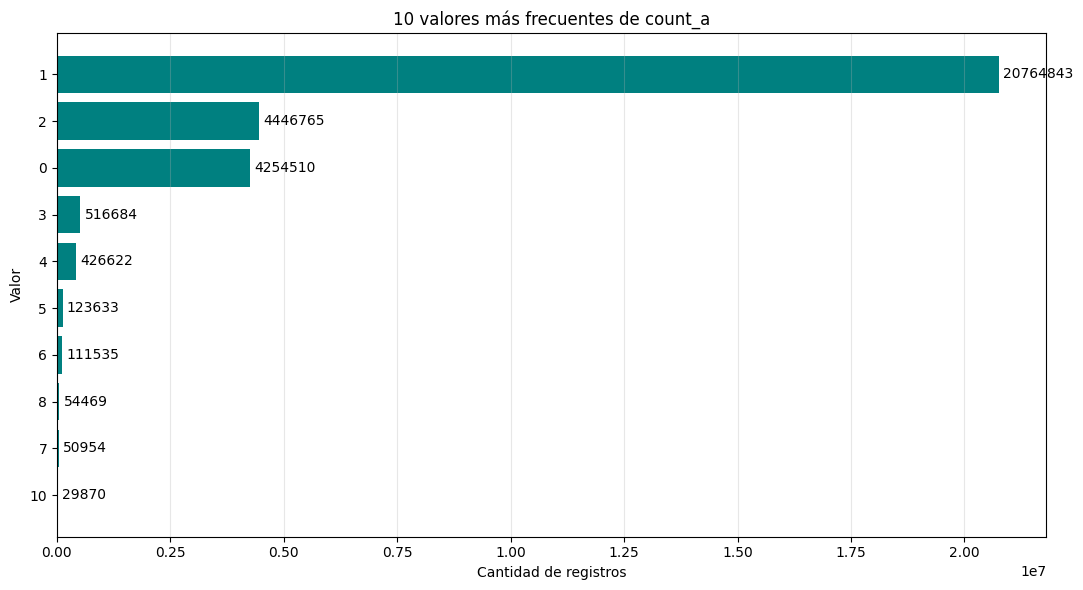

,etiqueta,cantidad
0,1,20764843
1,2,4446765
2,0,4254510
3,3,516684
4,4,426622
5,5,123633
6,6,111535
7,8,54469
8,7,50954
9,10,29870


In [ ]:
# 4. Valores más frecuentes de count_a
graficar_top10(
    campos=["count_a"],
    etiqueta="count_a",
    titulo="10 valores más frecuentes de count_a"
)



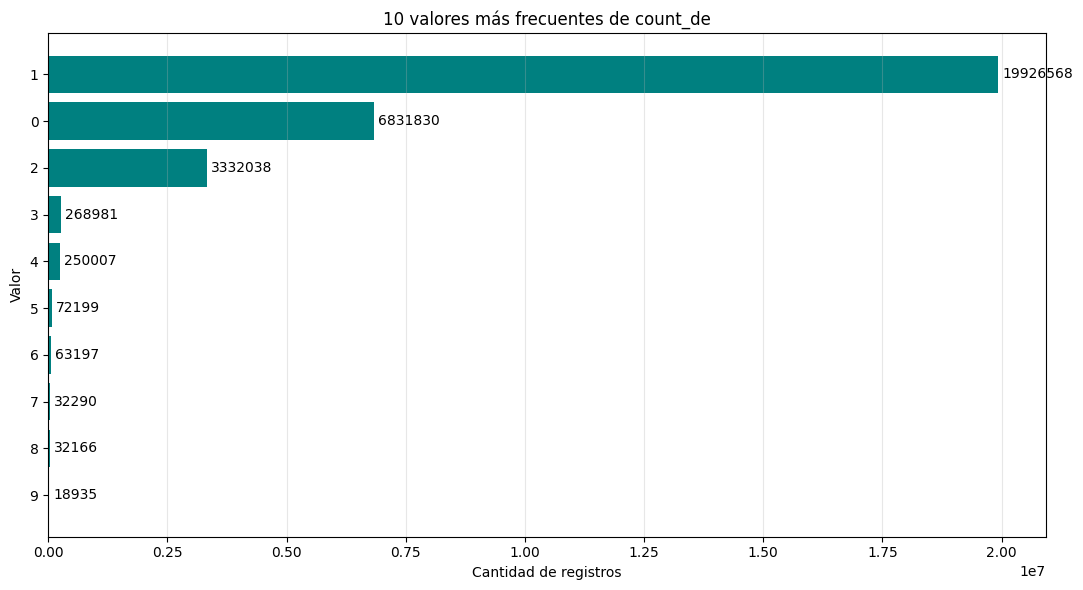

,etiqueta,cantidad
0,1,19926568
1,0,6831830
2,2,3332038
3,3,268981
4,4,250007
5,5,72199
6,6,63197
7,7,32290
8,8,32166
9,9,18935


In [ ]:
# 5. Valores más frecuentes de count_de
graficar_top10(
    campos=["count_de"],
    etiqueta="count_de",
    titulo="10 valores más frecuentes de count_de"
)

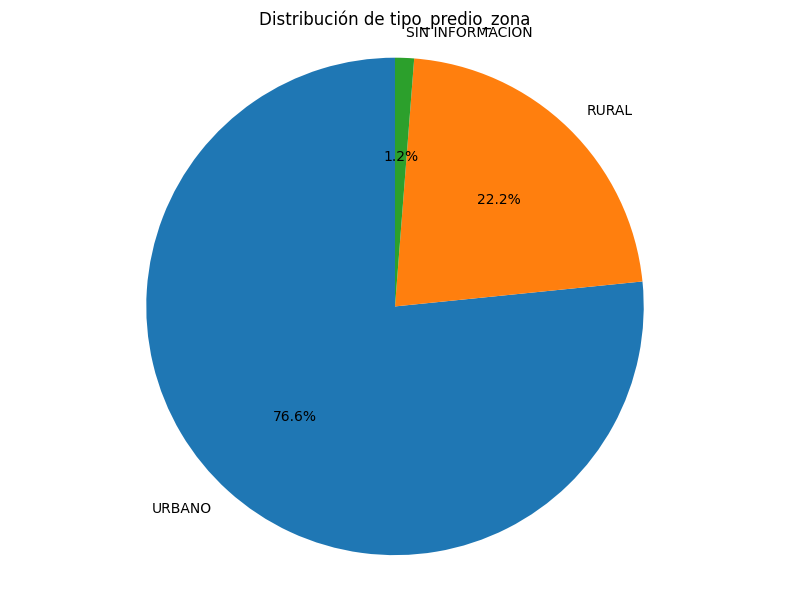

,categoria,cantidad
0,URBANO,23672128
1,RURAL,6851108
2,SIN INFORMACION,380012


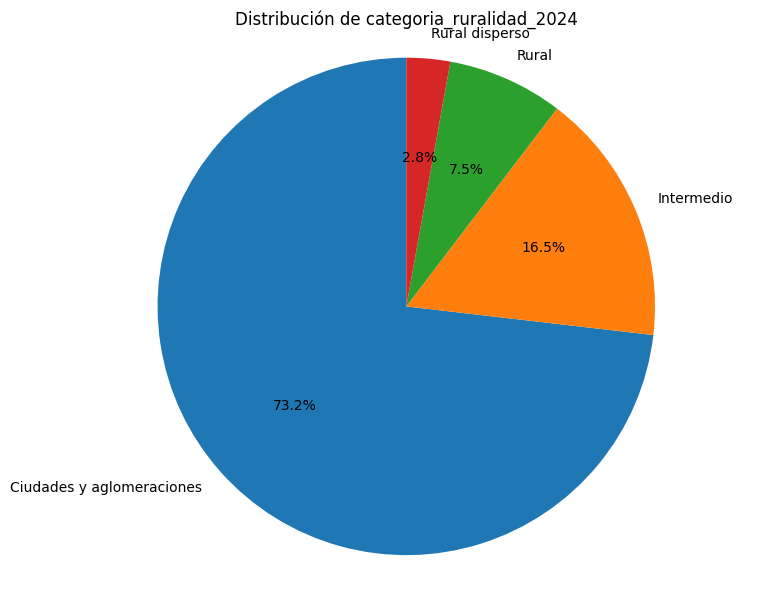

,categoria,cantidad
0,Ciudades y aglomeraciones,22609918
1,Intermedio,5090370
2,Rural,2325694
3,Rural disperso,877266


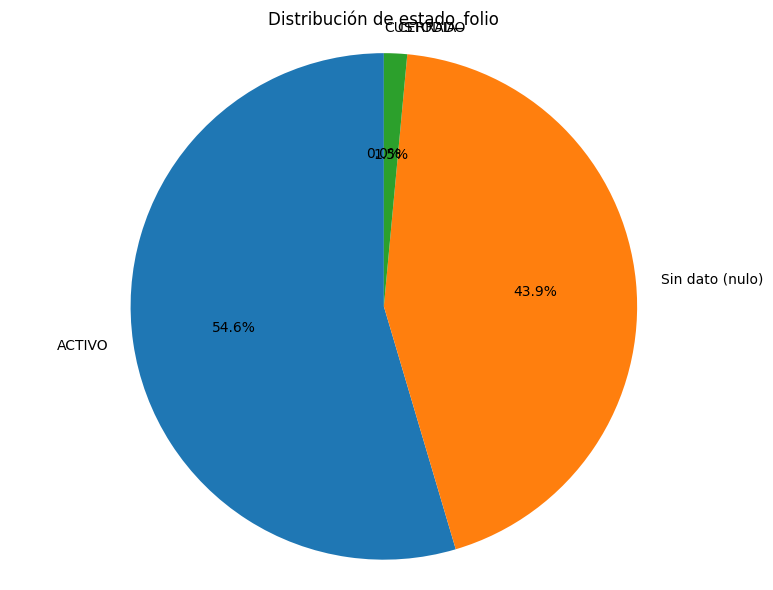

,categoria,cantidad
0,ACTIVO,16867436
1,Sin dato (nulo),13579939
2,CERRADO,455853
3,CUSTODIA,20


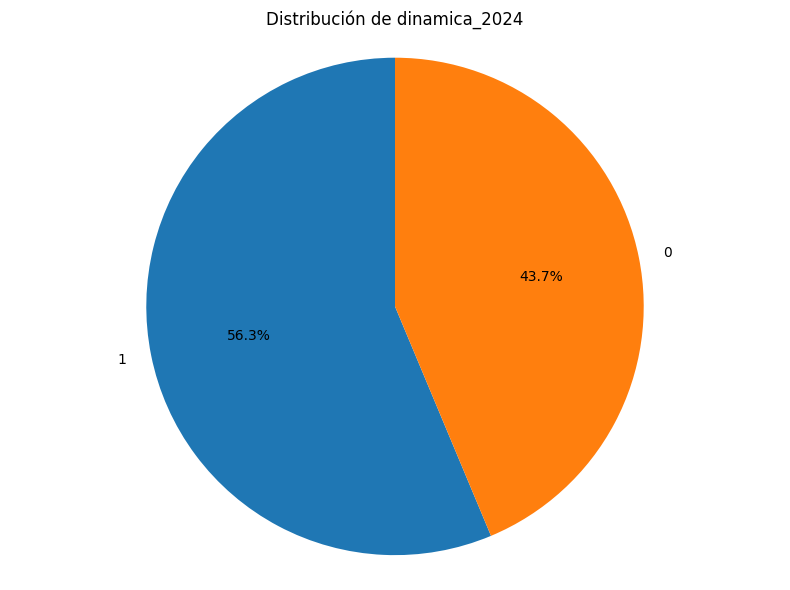

,categoria,cantidad
0,1,17400845
1,0,13502403


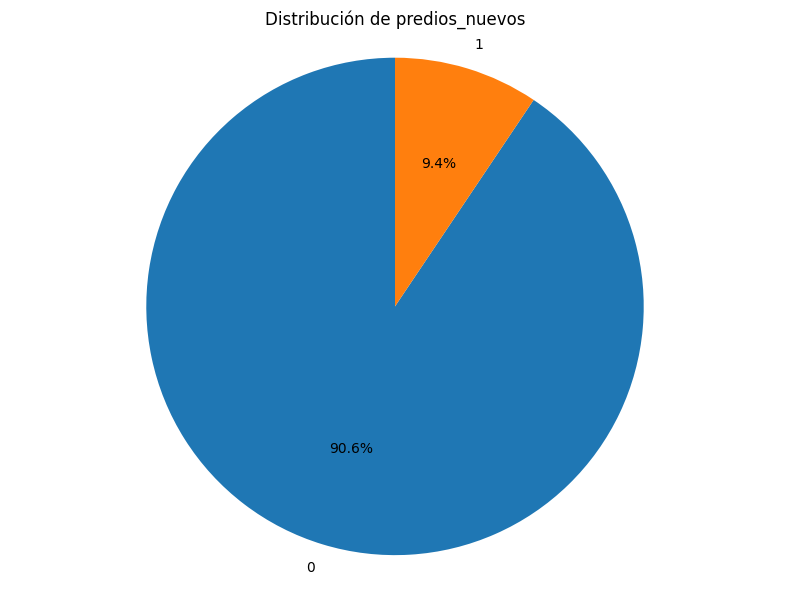

,categoria,cantidad
0,0,27995187
1,1,2908061


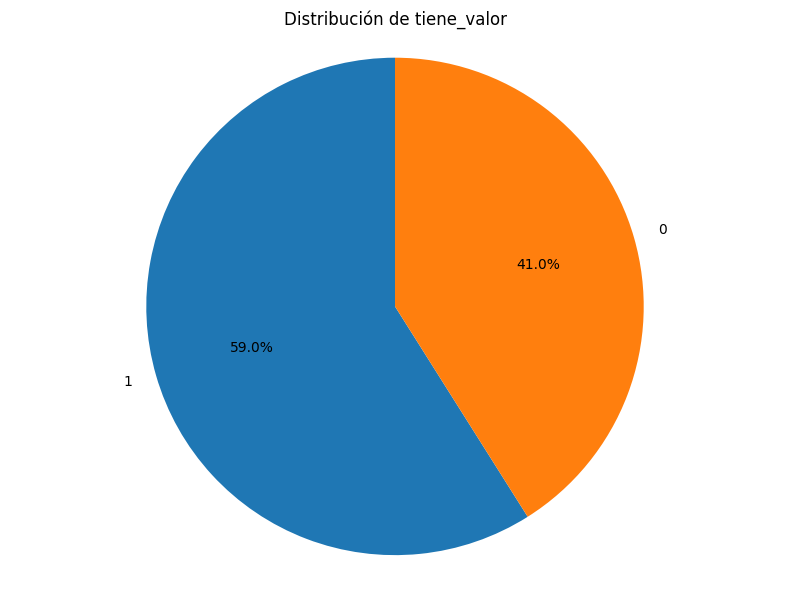

,categoria,cantidad
0,1,18219652
1,0,12683596


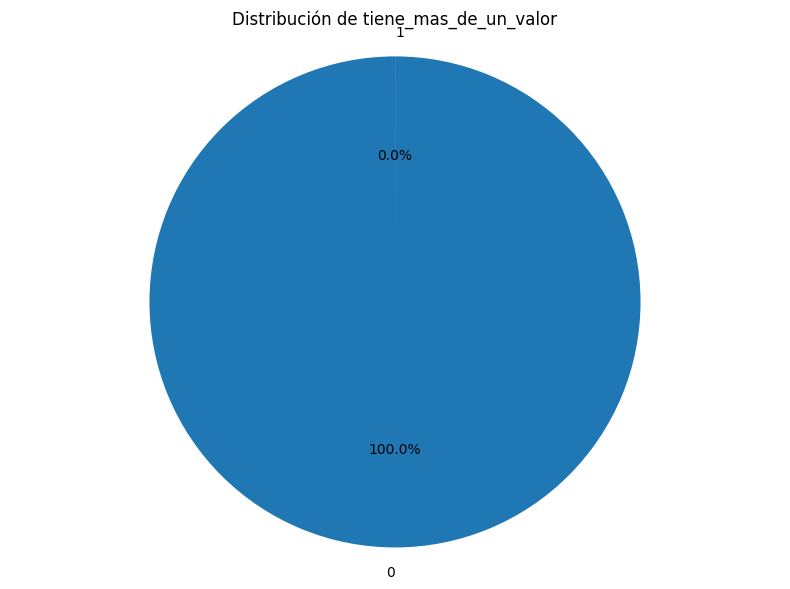

,categoria,cantidad
0,0,30902219
1,1,1029


In [ ]:
variables = [
    "tipo_predio_zona",
    "categoria_ruralidad_2024",
    "estado_folio",
    "dinamica_2024",
    "predios_nuevos",
    "tiene_valor",
    "tiene_mas_de_un_valor"
]

def graficar_pie(campo, max_categorias=8):
    resultado = consultar({
        "$select": f"{campo}, count(*) as cantidad",
        "$group": campo,
        "$order": "cantidad DESC"
    })

    df = pd.DataFrame(resultado)

    if df.empty:
        print(f"No hay datos para {campo}")
        return

    df["cantidad"] = pd.to_numeric(df["cantidad"], errors="coerce").fillna(0)

    # Etiqueta los valores nulos y vacíos
    def etiqueta(valor):
        if pd.isna(valor):
            return "Sin dato (nulo)"
        valor = str(valor).strip()
        return valor if valor else "Vacío"

    df["categoria"] = df[campo].apply(etiqueta)
    df = df.groupby("categoria", as_index=False)["cantidad"].sum()
    df = df.sort_values("cantidad", ascending=False)

    # Agrupa categorías poco frecuentes para facilitar la lectura
    if len(df) > max_categorias:
        principales = df.head(max_categorias).copy()
        otros = df.iloc[max_categorias:]["cantidad"].sum()

        if otros > 0:
            principales = pd.concat([
                principales,
                pd.DataFrame([{
                    "categoria": "Otros",
                    "cantidad": otros
                }])
            ], ignore_index=True)

        df = principales

    plt.figure(figsize=(8, 6))
    plt.pie(
        df["cantidad"],
        labels=df["categoria"],
        autopct="%1.1f%%",
        startangle=90
    )
    plt.title(f"Distribución de {campo}")
    plt.axis("equal")
    plt.tight_layout()
    plt.show()

    display(df.sort_values("cantidad", ascending=False).reset_index(drop=True))


for variable in variables:
    graficar_pie(variable)


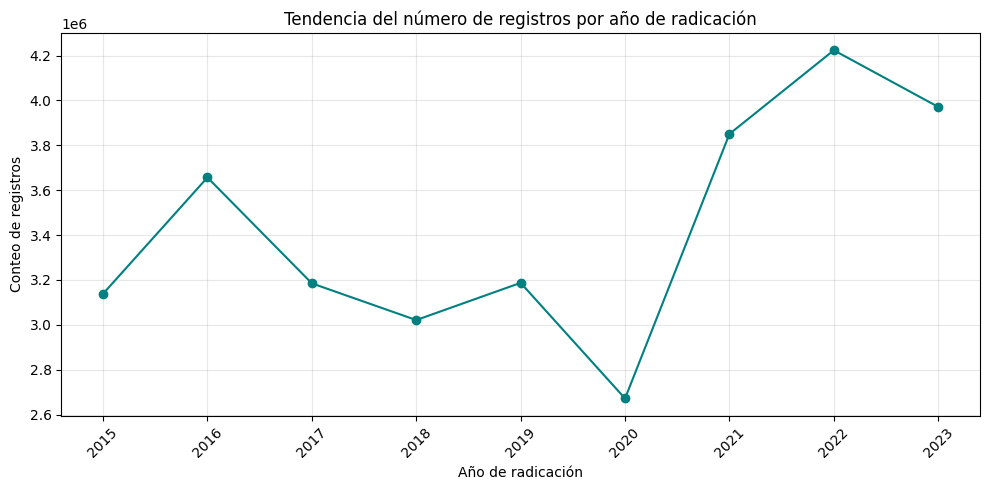

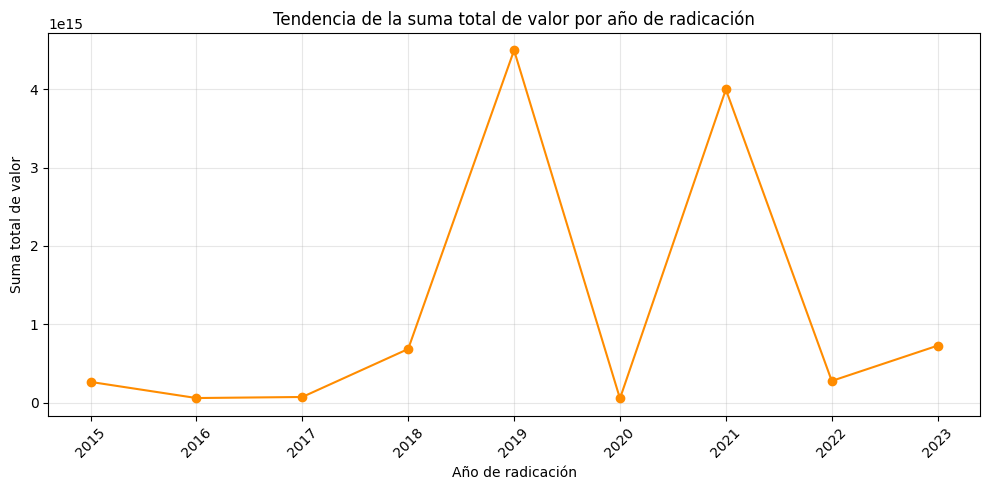

In [ ]:
# 1. Tendencia del conteo de registros por año
conteos = consultar({
    "$select": "year_radica, count(*) as conteo",
    "$where": "year_radica IS NOT NULL",
    "$group": "year_radica"
})

df_conteos = pd.DataFrame(conteos)
df_conteos["year_radica"] = pd.to_numeric(
    df_conteos["year_radica"], errors="coerce"
)
df_conteos["conteo"] = pd.to_numeric(df_conteos["conteo"], errors="coerce")
df_conteos = df_conteos.dropna().sort_values("year_radica")

plt.figure(figsize=(10, 5))
plt.plot(
    df_conteos["year_radica"],
    df_conteos["conteo"],
    marker="o",
    color="teal"
)
plt.title("Tendencia del número de registros por año de radicación")
plt.xlabel("Año de radicación")
plt.ylabel("Conteo de registros")
plt.xticks(df_conteos["year_radica"], rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Tendencia de la suma total de valor por año
sumas = consultar({
    "$select": "year_radica, sum(valor) as valor_total",
    "$where": "year_radica IS NOT NULL AND valor IS NOT NULL",
    "$group": "year_radica"
})

df_sumas = pd.DataFrame(sumas)
df_sumas["year_radica"] = pd.to_numeric(
    df_sumas["year_radica"], errors="coerce"
)
df_sumas["valor_total"] = pd.to_numeric(
    df_sumas["valor_total"], errors="coerce"
)
df_sumas = df_sumas.dropna().sort_values("year_radica")

plt.figure(figsize=(10, 5))
plt.plot(
    df_sumas["year_radica"],
    df_sumas["valor_total"],
    marker="o",
    color="darkorange"
)
plt.title("Tendencia de la suma total de valor por año de radicación")
plt.xlabel("Año de radicación")
plt.ylabel("Suma total de valor")
plt.xticks(df_sumas["year_radica"], rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


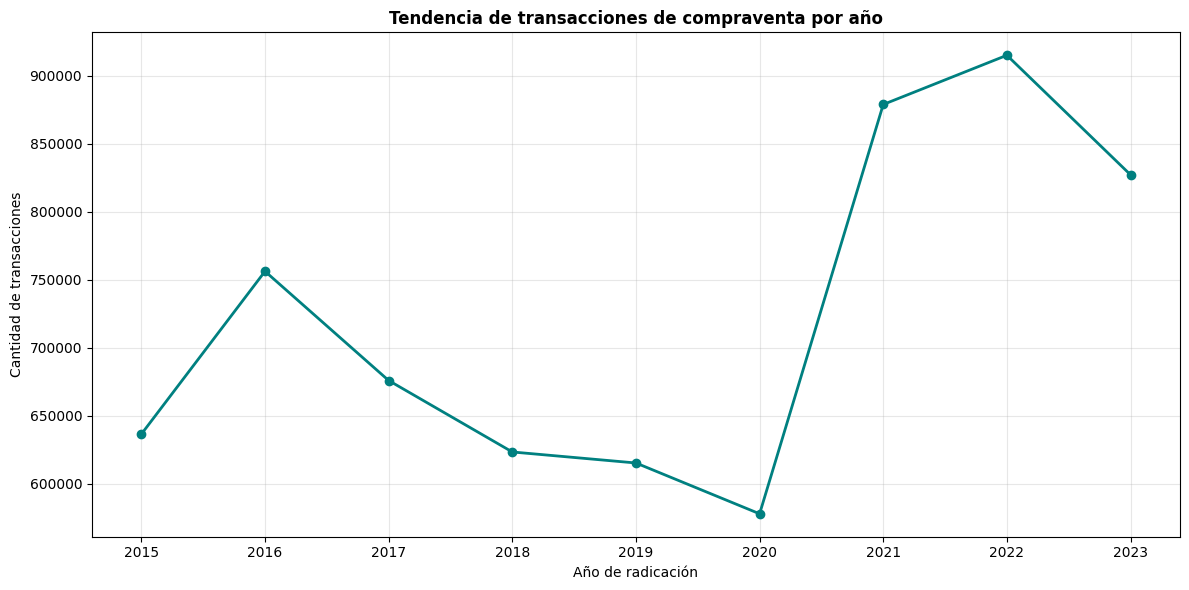

,anio,transacciones
0,2015,636404
1,2016,756183
2,2017,675850
3,2018,623290
4,2019,615184
5,2020,577812
6,2021,878897
7,2022,915097
8,2023,827160


In [ ]:
# Contar las compraventas por año de radicación
resultado = consultar({
    "$select": "year_radica, count(*) as cantidad",
    "$where": (
        "upper(nombre_natujur) LIKE '%COMPRAVENTA%' "
        "AND year_radica IS NOT NULL"
    ),
    "$group": "year_radica"
})

df_tendencia_compraventas = pd.DataFrame(resultado)

if df_tendencia_compraventas.empty:
    print("No se encontraron registros de compraventa con año informado.")
else:
    # Preparar los campos como valores numéricos
    df_tendencia_compraventas["anio"] = pd.to_numeric(
        df_tendencia_compraventas["year_radica"],
        errors="coerce"
    )

    df_tendencia_compraventas["cantidad"] = pd.to_numeric(
        df_tendencia_compraventas["cantidad"],
        errors="coerce"
    )

    # Eliminar valores que no se puedan ordenar como año o cantidad
    df_tendencia_compraventas = (
        df_tendencia_compraventas
        .dropna(subset=["anio", "cantidad"])
        .sort_values("anio")
    )

    df_tendencia_compraventas["anio"] = (
        df_tendencia_compraventas["anio"].astype(int)
    )

    # Graficar la tendencia
    plt.figure(figsize=(12, 6))
    plt.plot(
        df_tendencia_compraventas["anio"],
        df_tendencia_compraventas["cantidad"],
        marker="o",
        linewidth=2,
        color="teal"
    )

    plt.title("Tendencia de transacciones de compraventa por año")
    plt.xlabel("Año de radicación")
    plt.ylabel("Cantidad de transacciones")
    plt.xticks(df_tendencia_compraventas["anio"])
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Mostrar la tabla usada para construir la gráfica
    display(
        df_tendencia_compraventas[["anio", "cantidad"]]
        .rename(columns={"cantidad": "transacciones"})
        .reset_index(drop=True)
    )


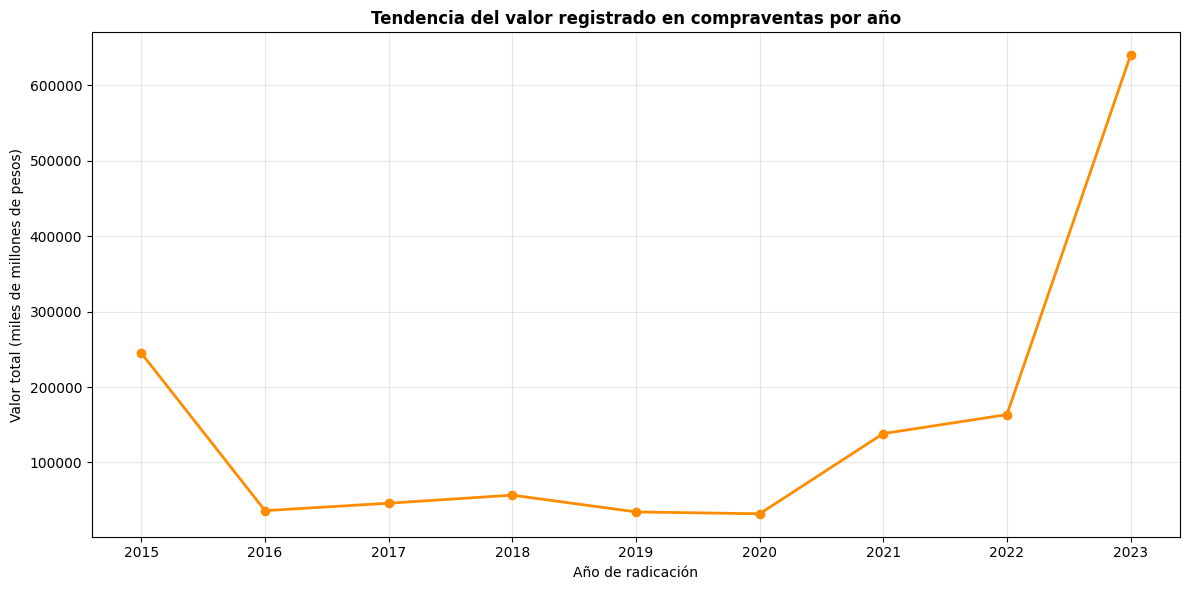

,año,valor_total_pesos,registros_incluidos
0,2015,2.448472e+14,415648
1,2016,3.617926e+13,430848
2,2017,4.599031e+13,403149
3,2018,5.669691e+13,393686
4,2019,3.448909e+13,379296
5,2020,3.198012e+13,323056
6,2021,1.382701e+14,744492
7,2022,1.634201e+14,911914
8,2023,6.396544e+14,823488


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Sumar el valor registrado por año para operaciones de compraventa
resultado = consultar({
    "$select": (
        "year_radica, "
        "sum(valor) as valor_total, "
        "count(valor) as registros_con_valor"
    ),
    "$where": (
        "upper(nombre_natujur) LIKE '%COMPRAVENTA%' "
        "AND year_radica IS NOT NULL "
        "AND valor IS NOT NULL"
    ),
    "$group": "year_radica"
})

df_valor_compraventas = pd.DataFrame(resultado)

if df_valor_compraventas.empty:
    print("No se encontraron compraventas con año y valor informado.")
else:
    df_valor_compraventas["anio"] = pd.to_numeric(
        df_valor_compraventas["year_radica"],
        errors="coerce"
    )

    df_valor_compraventas["valor_total"] = pd.to_numeric(
        df_valor_compraventas["valor_total"],
        errors="coerce"
    )

    df_valor_compraventas["registros_con_valor"] = pd.to_numeric(
        df_valor_compraventas["registros_con_valor"],
        errors="coerce"
    )

    df_valor_compraventas = (
        df_valor_compraventas
        .dropna(subset=["anio", "valor_total"])
        .sort_values("anio")
    )

    df_valor_compraventas["anio"] = (
        df_valor_compraventas["anio"].astype(int)
    )

    # Expresar el total en miles de millones de pesos para facilitar la lectura
    df_valor_compraventas["valor_total_miles_millones"] = (
        df_valor_compraventas["valor_total"] / 1_000_000_000
    )

    plt.figure(figsize=(12, 6))
    plt.plot(
        df_valor_compraventas["anio"],
        df_valor_compraventas["valor_total_miles_millones"],
        marker="o",
        linewidth=2,
        color="darkorange"
    )

    plt.title("Tendencia del valor registrado en compraventas por año")
    plt.xlabel("Año de radicación")
    plt.ylabel("Valor total (miles de millones de pesos)")
    plt.xticks(df_valor_compraventas["anio"])
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    display(
        df_valor_compraventas[
            ["anio", "valor_total", "registros_con_valor"]
        ].rename(columns={
            "anio": "año",
            "valor_total": "valor_total_pesos",
            "registros_con_valor": "registros_incluidos"
        }).reset_index(drop=True)
    )


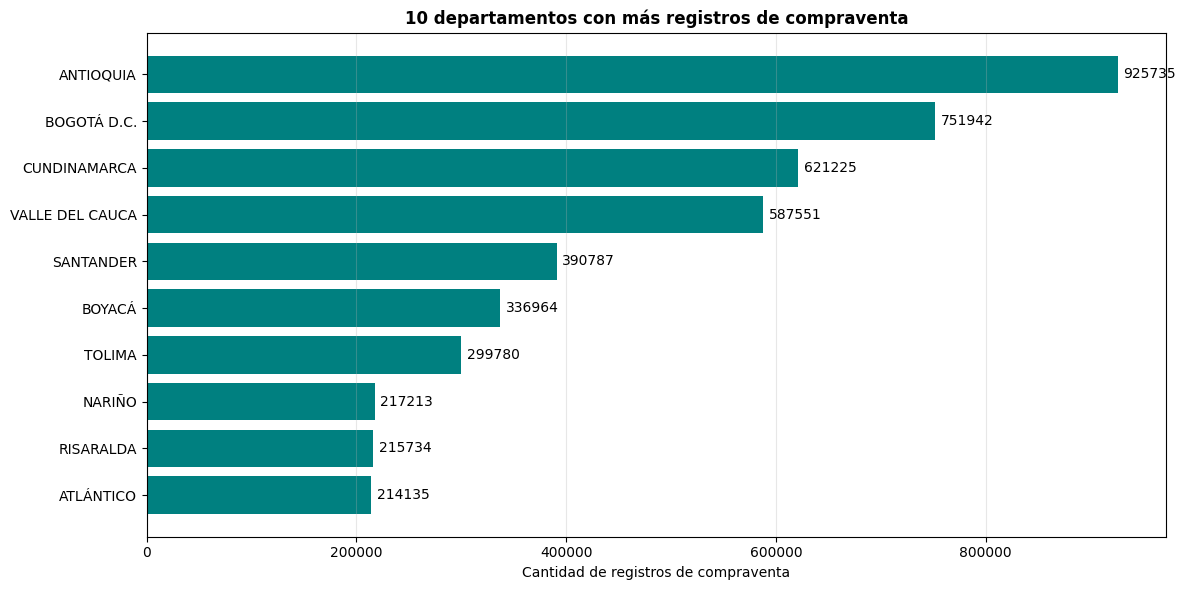

,departamento,cantidad
0,ANTIOQUIA,925735
1,BOGOTÁ D.C.,751942
2,CUNDINAMARCA,621225
3,VALLE DEL CAUCA,587551
4,SANTANDER,390787
5,BOYACÁ,336964
6,TOLIMA,299780
7,NARIÑO,217213
8,RISARALDA,215734
9,ATLÁNTICO,214135


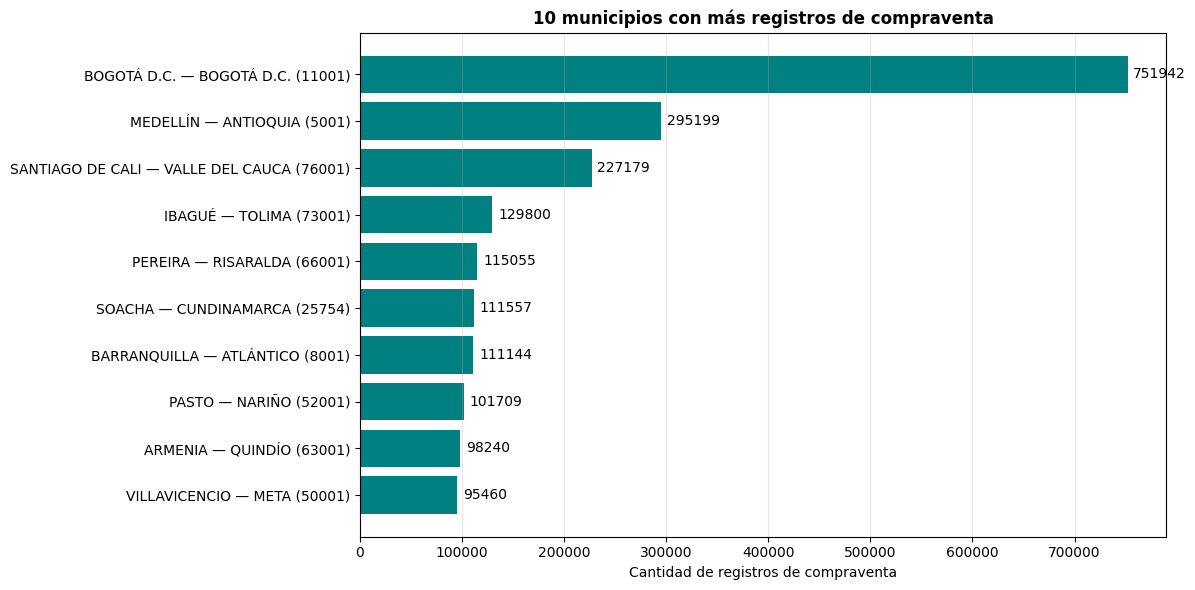

,municipio,departamento,divipola,cantidad
0,BOGOTÁ D.C.,BOGOTÁ D.C.,11001,751942
1,MEDELLÍN,ANTIOQUIA,5001,295199
2,SANTIAGO DE CALI,VALLE DEL CAUCA,76001,227179
3,IBAGUÉ,TOLIMA,73001,129800
4,PEREIRA,RISARALDA,66001,115055
5,SOACHA,CUNDINAMARCA,25754,111557
6,BARRANQUILLA,ATLÁNTICO,8001,111144
7,PASTO,NARIÑO,52001,101709
8,ARMENIA,QUINDÍO,63001,98240
9,VILLAVICENCIO,META,50001,95460


In [ ]:
filtro_compraventa = "upper(nombre_natujur) LIKE '%COMPRAVENTA%'"


def graficar_top10_compraventas(campos, etiqueta, titulo):
    """Consulta y grafica los 10 grupos con más registros de compraventa."""

    resultado = consultar({
        "$select": f"{campos}, count(*) as cantidad",
        "$where": f"{filtro_compraventa} AND {campos.split(',')[0]} IS NOT NULL",
        "$group": campos,
        "$order": "cantidad DESC",
        "$limit": 10
    })

    df_top = pd.DataFrame(resultado)

    if df_top.empty:
        print(f"No se encontraron resultados para: {titulo}")
        return

    df_top["cantidad"] = pd.to_numeric(
        df_top["cantidad"],
        errors="coerce"
    )

    # Crear etiquetas legibles
    if etiqueta == "departamento":
        df_top["etiqueta"] = df_top["departamento"].astype(str)

    elif etiqueta == "municipio":
        df_top["etiqueta"] = (
            df_top["municipio"].astype(str)
            + " — "
            + df_top["departamento"].astype(str)
            + " ("
            + df_top["divipola"].astype(str)
            + ")"
        )

    # Orden ascendente para que la barra más alta aparezca arriba
    df_top = df_top.sort_values("cantidad", ascending=True)

    plt.figure(figsize=(12, 6))
    barras = plt.barh(
        df_top["etiqueta"],
        df_top["cantidad"],
        color="teal"
    )

    plt.title(titulo)
    plt.xlabel("Cantidad de registros de compraventa")
    plt.ylabel("")
    plt.grid(axis="x", alpha=0.3)
    plt.bar_label(barras, fmt="%.0f", padding=4)
    plt.tight_layout()
    plt.show()

    # Mostrar tabla en orden descendente
    columnas_mostrar = (
        ["departamento", "cantidad"]
        if etiqueta == "departamento"
        else ["municipio", "departamento", "divipola", "cantidad"]
    )

    display(
        df_top.sort_values("cantidad", ascending=False)[columnas_mostrar]
        .reset_index(drop=True)
    )


# Top 10 departamentos
graficar_top10_compraventas(
    campos="departamento",
    etiqueta="departamento",
    titulo="10 departamentos con más registros de compraventa"
)

# Top 10 municipios, identificados también por departamento y código DIVIPOLA
graficar_top10_compraventas(
    campos="municipio, departamento, divipola",
    etiqueta="municipio",
    titulo="10 municipios con más registros de compraventa"
)


### Conclusión
En este punto vemos si los datos mediante técnicas de análisis estadísticas generan resultados entendibles. Para ello, se separan las variables por tipo categórica y numérica.

Por lo anterior, para aquellas características numéricas tales como: 'num_anotacion', 'dinamica_2024', 'cod_natujur', 'count_a', 'count_de', 'predios_nuevos', 'tiene_valor', 'tiene_mas_de_un_valor', 'valor'. Analizamos su media, mínimo, máximo, cantidad, moda, mediana y se hizo gráfica de boxplot. De esto, podemos concluir lo siguiente:
- num_anotacion es un valor que indica como el registro de transacción que lleva, pero no genera mucho valor
- dinamica_2024, predios_nuevos, tiene_valor y tiene_mas_de_un_valor son booleanos, son valores de 0 y 1 y no tanto numérico o enteros.
- cod_natujur es un código que no tiene sentido calcular estas medidas descriptivas
- también es importante validar count_a y count_de porque muestra una cantidad maxima de 10791 y 6744 respectivamente valores alto como de testigos que estuvieron presente para esa situación y si es compraventa o no
- Por último tenemos valor que es importante y vemos que tiene un mínimo de 0 hasta 3789999940000000, aunque es un registro que no está en todos los registros, por lo que es necesario validar si ese valor vacío o nulo sería igual a 0 o porque ese dato no estaría, también este campo tiene muchos outlier por lo que se hace importante validar esta data y que tanto valor nos puede generar.

También se realiza el análisis y un poco la claridad sobre las variables categóricas haciendo gráficas por ejemplo de barras y pie chart que nos permite ver el comportamiento de las variables.

Por ejemplo vemos los 10 departamentos donde hay mas registros y entre ellos está Antioquia y Bogotá. Luego hacemos el ejercicio con los municipios y el que va primero es Bogotá y le sigue una parte de Medellín.

- En pie chart realizado tenemos en tipo predio zona que URBANO hay un 76.6%, Rural 22.2% y 1.2% de SIN INFORMACIÓN.

- categoría ruralidad 2024 donde mas prima son ciudades y aglomeraciones.
- En estado folio hay valores ACTIVO de 54.6% y se encuentra sin valor y sin dato el 43.9%
- dinámica 2024 56% son 1 y 0 43%
- Distribución predios nuevos están en 0 con 90% y 1 con 9.4%
- Tiene valor 1 en 59% y 0 en 41%
- Tiene mas de 1 valor 0 en 100% y 1 en 0%

por último tenemos las tendencias donde vemos que del 2017 - 2019 hubo una estabilidad en transacciones pero luego 2020 a 2022 aumentó la cantidad de transacciones y en 2023 muestra que baja un poco ese comportamiento

en cuanto a valor vemos que hay unos picos entre 2019 y 2021 exageradamente el valor cambia.

También se hizo un análisis solo en aquellos donde el nombre natural contiene COMPRAVENTA para ver el comportamiento de los departamentos, municipios.

## Formato

In [ ]:
display(pd.DataFrame(columnas))

,campo,nombre,tipo
0,pk,PK,text
1,matricula,MATRICULA,text
2,fecha_radica_texto,FECHA_RADICA_TEXTO,text
3,fecha_apertura_texto,FECHA_APERTURA_TEXTO,text
4,year_radica,YEAR_RADICA,text
5,orip,ORIP,text
6,divipola,DIVIPOLA,text
7,departamento,DEPARTAMENTO,text
8,municipio,MUNICIPIO,text
9,tipo_predio_zona,TIPO_PREDIO_ZONA,text


### Conclusión
- A tener en cuenta es que las fechas como fecha_radica_texto y fecha_apertura_texto están almacenadas como texto y corresponden a fecha
- También se tiene la variable cod_natujur que es numérico pero al ser un código puede ser necesario que sea de tipo texto para análisis y gráficas
- También year_radica es como texto cuando para análisis es  mejor tenerlo de tipo numérico además que solo abarca valores desde 2015 - 2023

# Limpieza de datos

## Filtros e imputaciones

In [ ]:
SOLO_BOGOTA = True
TAMANO_PAGINA = 50000


def consultar(params, intentos=5):
    """Consulta Socrata y reintenta si hay errores temporales o límite de solicitudes."""
    for intento in range(intentos):
        respuesta = requests.get(API, params=params, timeout=120)

        if respuesta.status_code == 429 or respuesta.status_code >= 500:
            time.sleep(2 * (intento + 1))
            continue

        respuesta.raise_for_status()
        return respuesta.json()

    respuesta.raise_for_status()


# La columna year_radica está almacenada como texto en la fuente.
# filtros = [
#     "year_radica IN ('2021', '2022', '2023')",
#     "upper(nombre_natujur) LIKE '%COMPRAVENTA%'"
# ]

filtros = [
    "upper(nombre_natujur) LIKE '%COMPRAVENTA%'"
]

if SOLO_BOGOTA:
    filtros.append("municipio = 'BOGOTÁ D.C.'")

where = " AND ".join(filtros)


# 1. Contar los registros que cumplen los filtros antes de descargarlos
conteo = consultar({
    "$select": "count(*) as total",
    "$where": where
})

total_esperado = int(conteo[0]["total"])
print("Registros que cumplen los filtros:", f"{total_esperado:,}")


# 2. Seleccionar todas las columnas excepto las que se quieren eliminar
columnas_eliminar = {
    "numero_catastral",
    "numero_catastral_antiguo"
}

campos_descarga = [
    c["campo"]
    for c in columnas
    if c.get("campo")
    and not c["campo"].startswith(":")
    and c["campo"] not in columnas_eliminar
]

# Descargar por páginas, ordenando por pk para mantener un orden reproducible
registros = []
offset = 0

while offset < total_esperado:
    pagina = consultar({
        "$select": ", ".join(campos_descarga),
        "$where": where,
        "$order": "pk ASC",
        "$limit": TAMANO_PAGINA,
        "$offset": offset
    })

    if not pagina:
        break

    registros.extend(pagina)
    offset += len(pagina)

    print(f"Descargados: {len(registros):,} de {total_esperado:,}")

    # Pausa breve para reducir la probabilidad de exceder el límite de solicitudes
    time.sleep(0.2)


# 3. Crear el DataFrame con todas las transacciones filtradas
df_compraventas = pd.DataFrame.from_records(registros)

print("\nDimensiones de df_compraventas:", df_compraventas.shape)


Registros que cumplen los filtros: 338,123
Descargados: 50,000 de 338,123
Descargados: 100,000 de 338,123
Descargados: 150,000 de 338,123
Descargados: 200,000 de 338,123
Descargados: 250,000 de 338,123
Descargados: 300,000 de 338,123
Descargados: 338,123 de 338,123

Dimensiones de df_compraventas: (338123, 23)


## Elimina duplicados por matrícula, Normalización de fechas

In [ ]:
# Crear el DataFrame a partir de los registros descargados
df_compraventas = pd.DataFrame.from_records(registros).copy()

filas_iniciales = len(df_compraventas)

# 1. Normalizar matrícula sin quitar ceros iniciales
if "matricula" in df_compraventas.columns:
    df_compraventas["matricula"] = (
        df_compraventas["matricula"]
        .astype("string")
        .str.strip()
    )

    df_compraventas.loc[
        df_compraventas["matricula"].eq(""),
        "matricula"
    ] = pd.NA


# 2. Identificar y eliminar filas con fecha de apertura centinela 01-01-1800
fechas_centinela = {
    "01-01-1800",
    "01/01/1800",
    "1800-01-01",
    "1800-01-01 00:00:00"
}

fecha_apertura_original = (
    df_compraventas["fecha_apertura_texto"]
    .astype("string")
    .str.strip()
)

mascara_centinela = fecha_apertura_original.isin(fechas_centinela)

# Guardar las filas excluidas para poder documentarlas
df_registros_eliminados = df_compraventas.loc[mascara_centinela].copy()

# Excluirlas del DataFrame de trabajo
df_compraventas = df_compraventas.loc[~mascara_centinela].copy()

print("Filas eliminadas por fecha centinela:",
      f"{len(df_registros_eliminados):,}")


# 3. Convertir los formatos de fecha observados
def convertir_fecha_mixta(serie):
    texto = serie.astype("string").str.strip()

    fecha = pd.Series(
        pd.NaT,
        index=serie.index,
        dtype="datetime64[ns]"
    )

    formatos = [
        "%Y-%m-%d %H:%M:%S",  # 2016-03-29 00:00:00
        "%d/%m/%Y",           # 29/09/2016
        "%d/%m/%y",           # 05/08/22 -> 5 de agosto de 2022
        "%Y-%m-%d",           # 2016-03-29
        "%d-%m-%Y"            # 01-01-1800
    ]

    for formato in formatos:
        pendientes = fecha.isna() & texto.notna() & texto.ne("")

        fecha.loc[pendientes] = pd.to_datetime(
            texto.loc[pendientes],
            format=formato,
            errors="coerce"
        )

    return fecha.dt.normalize()


# Convertir y registrar cuántas fechas no se interpretaron
calidad_fechas = []

for campo in ["fecha_radica_texto", "fecha_apertura_texto"]:
    if campo not in df_compraventas.columns:
        continue

    original = df_compraventas[campo].copy()
    convertida = convertir_fecha_mixta(original)

    texto_original = original.astype("string").str.strip()
    no_convertidas = (
        texto_original.notna()
        & texto_original.ne("")
        & convertida.isna()
    )

    calidad_fechas.append({
        "campo": campo,
        "valores_originales_no_vacios": int(
            (texto_original.notna() & texto_original.ne("")).sum()
        ),
        "fechas_no_convertidas": int(no_convertidas.sum())
    })

    df_compraventas[campo] = convertida


# 4. Convertir year_radica a entero nullable
if "year_radica" in df_compraventas.columns:
    df_compraventas["year_radica"] = pd.to_numeric(
        df_compraventas["year_radica"],
        errors="coerce"
    ).astype("Int64")


# 5. Eliminar las columnas catastrales solicitadas
columnas_eliminar = [
    "numero_catastral",
    "numero_catastral_antiguo"
]

df_compraventas = df_compraventas.drop(
    columns=columnas_eliminar,
    errors="ignore"
)


# 6. Elegir el registro más reciente por matrícula
# Los registros sin matrícula se conservan aparte: no pueden compararse por matrícula.
df_sin_matricula = df_compraventas[
    df_compraventas["matricula"].isna()
].copy()

df_con_matricula = df_compraventas[
    df_compraventas["matricula"].notna()
].copy()

# La fecha ya está convertida a tipo fecha, por lo que el orden cronológico es correcto.
# pk ascendente solo sirve como desempate reproducible si dos filas tienen la misma fecha;
# no significa que esa fila haya ocurrido más tarde.
df_con_matricula = df_con_matricula.sort_values(
    ["matricula", "fecha_radica_texto", "pk"],
    ascending=[True, False, True],
    na_position="last"
)

df_ultima_por_matricula = (
    df_con_matricula
    .drop_duplicates(subset=["matricula"], keep="first")
    .copy()
)

# Añadir de vuelta todas las filas sin matrícula, sin deduplicarlas
df_compraventas_unicas = pd.concat(
    [df_ultima_por_matricula, df_sin_matricula],
    ignore_index=True
)


# 7. Resumen de resultados
print("\nFilas iniciales descargadas:",
      f"{filas_iniciales:,}")
print("Filas después de eliminar fechas centinela:",
      f"{len(df_compraventas):,}")
print("Filas sin matrícula conservadas:",
      f"{len(df_sin_matricula):,}")
print("Filas en el resultado con una fila por matrícula:",
      f"{len(df_compraventas_unicas):,}")
print("Matrículas repetidas en el resultado:",
      int(
          df_compraventas_unicas.loc[
              df_compraventas_unicas["matricula"].notna(),
              "matricula"
          ].duplicated().sum()
      ))

print("\nAños presentes:")
print(sorted(
    df_compraventas_unicas["year_radica"]
    .dropna()
    .unique()
    .tolist()
))

display(pd.DataFrame(calidad_fechas))
display(df_compraventas_unicas.head())


Filas eliminadas por fecha centinela: 39

Filas iniciales descargadas: 338,123
Filas después de eliminar fechas centinela: 338,084
Filas sin matrícula conservadas: 0
Filas en el resultado con una fila por matrícula: 316,887
Matrículas repetidas en el resultado: 0

Años presentes:
[2021, 2022, 2023]


,campo,valores_originales_no_vacios,fechas_no_convertidas
0,fecha_radica_texto,338084,0
1,fecha_apertura_texto,324581,0


,pk,matricula,fecha_radica_texto,fecha_apertura_texto,year_radica,orip,divipola,departamento,municipio,tipo_predio_zona,...,dinamica_2024,cod_natujur,nombre_natujur,documento_justificativo,count_a,count_de,predios_nuevos,tiene_valor,tiene_mas_de_un_valor,valor
0,11001-051-192963-00005-00125-2022,051-192963,2022-05-04,1999-05-29,2022,51,11001,BOGOTÁ D.C.,BOGOTÁ D.C.,URBANO,...,1,125,COMPRAVENTA,00-ESCRITURA 1467 DEL 19/04/22; SOACHA,1,1,0,1,0,35504000
1,11001-051-193158-00005-00125-2022,051-193158,2022-08-05,2000-06-30,2022,51,11001,BOGOTÁ D.C.,BOGOTÁ D.C.,URBANO,...,1,125,COMPRAVENTA,00-ESCRITURA 3056 DEL 15/07/22; SOACHA,2,2,0,1,0,145000000
2,11001-051-193199-00004-00125-2023,051-193199,2023-10-11,NaT,2023,51,11001,BOGOTÁ D.C.,BOGOTÁ D.C.,URBANO,...,1,125,COMPRAVENTA,00-ESCRITURA 3850 DE 23/09/2023; 051-SOACHA,1,4,0,1,0,205000000
3,11001-051-194897-00012-00125-2022,051-194897,2022-01-20,2011-12-15,2022,51,11001,BOGOTÁ D.C.,BOGOTÁ D.C.,URBANO,...,1,125,COMPRAVENTA,00-ESCRITURA 5059 DEL 27/12/21; SOACHA,1,1,0,1,0,83000000
4,11001-051-194902-00008-00125-2023,051-194902,2023-09-07,NaT,2023,51,11001,BOGOTÁ D.C.,BOGOTÁ D.C.,URBANO,...,1,125,COMPRAVENTA,00-ESCRITURA 950 DE 25/08/2023; 051-SOACHA,1,1,0,1,0,130000000


In [ ]:
# Columnas derivadas con un tipo que queremos mantener específicamente
campos_fecha = ["fecha_radica_texto", "fecha_apertura_texto"]
campo_anio = "year_radica"

# Obtener el tipo definido por Socrata para cada columna
tipos_fuente = {
    c["campo"]: c["tipo"]
    for c in columnas
    if c.get("campo") and c.get("tipo")
}

errores_conversion = []

# 1. Convertir los campos que Socrata define como numéricos
campos_numericos = [
    campo
    for campo, tipo in tipos_fuente.items()
    if tipo == "number" and campo in df_compraventas_unicas.columns
]

for campo in campos_numericos:
    original = df_compraventas_unicas[campo]
    texto = original.astype("string").str.strip()

    # Convierte cadenas numéricas a números; textos inválidos quedan como faltantes
    numerico = pd.to_numeric(texto, errors="coerce")

    invalido = (
        original.notna()
        & texto.ne("")
        & numerico.isna()
    )

    if invalido.sum() > 0:
        errores_conversion.append({
            "campo": campo,
            "valores_no_convertibles": int(invalido.sum()),
            "ejemplos": texto.loc[invalido].head(5).tolist()
        })

    # Si todos los valores válidos son enteros, usa entero nullable.
    # Si hay decimales, usa Float64.
    valores_validos = numerico.dropna()

    if valores_validos.empty or (valores_validos % 1 == 0).all():
        df_compraventas_unicas[campo] = numerico.astype("Int64")
    else:
        df_compraventas_unicas[campo] = numerico.astype("Float64")


# 2. Convertir columnas de texto a string
# Se conservan como texto los identificadores y códigos, incluidos los que
# puedan contener ceros iniciales.
campos_texto = [
    campo
    for campo, tipo in tipos_fuente.items()
    if tipo == "text"
    and campo in df_compraventas_unicas.columns
    and campo not in campos_fecha
    and campo != campo_anio
]

for campo in campos_texto:
    df_compraventas_unicas[campo] = (
        df_compraventas_unicas[campo].astype("string")
    )


# 3. Asegurar el tipo de fecha
for campo in campos_fecha:
    if campo in df_compraventas_unicas.columns:
        df_compraventas_unicas[campo] = pd.to_datetime(
            df_compraventas_unicas[campo],
            errors="coerce"
        ).dt.normalize()


# 4. Asegurar que year_radica sea entero nullable
if campo_anio in df_compraventas_unicas.columns:
    df_compraventas_unicas[campo_anio] = pd.to_numeric(
        df_compraventas_unicas[campo_anio],
        errors="coerce"
    ).astype("Int64")


# 5. Mostrar cualquier valor que no se haya podido convertir
print("Campos numéricos definidos por Socrata:", campos_numericos)

if errores_conversion:
    print("\nValores numéricos que no se pudieron convertir:")
    display(pd.DataFrame(errores_conversion))
else:
    print("\nNo se encontraron valores numéricos inválidos durante la conversión.")


# 6. Tabla con tipo original de Socrata y tipo final en pandas
resumen_tipos = pd.DataFrame({
    "tipo_fuente_socrata": pd.Series(tipos_fuente),
    "tipo_pandas": df_compraventas_unicas.dtypes.astype(str)
})

resumen_tipos.index.name = "campo"
resumen_tipos = resumen_tipos.reset_index()

display(resumen_tipos)

Campos numéricos definidos por Socrata: ['num_anotacion', 'dinamica_2024', 'cod_natujur', 'count_a', 'count_de', 'predios_nuevos', 'tiene_valor', 'tiene_mas_de_un_valor', 'valor']

No se encontraron valores numéricos inválidos durante la conversión.


,campo,tipo_fuente_socrata,tipo_pandas
0,categoria_ruralidad_2024,text,string
1,cod_natujur,number,Int64
2,count_a,number,Int64
3,count_de,number,Int64
4,departamento,text,string
5,dinamica_2024,number,Int64
6,divipola,text,string
7,documento_justificativo,text,string
8,estado_folio,text,string
9,fecha_apertura_texto,text,datetime64[ns]


### Conclusión
Se hicieron los siguientes ajustes
- se elimina columna numero_catastral_antiguo debido a que no tiene data y todo está nulo y vacío
- Se elimina columna numero_catastral debido a que no tiene data y todo está nulo y vacío
- nombre_natujur se deja todos aquellos que tengan valores como compraventa, esto es porque va enfocado al planetamiento de negocio.
- de year_radica vamos a traer la data del 2021 - 2023 y se cambia el formato para que sea numérico
- matricula se elimina los duplicados
- se normaliza la fecha fecha_radica_texto y fecha_apertura_texto y adicionalmente se trata aquellos datos de diferentes formatos. También si hay datos como del año 1800 se elimina ya que en esta hay pocos registros como 39 para eliminar y no afecta la data completa
- Por último se define el formato a cada uno de las variables para que sean enteros, string, float o date



# Entendimiento de los datos

## Análisis descriptivo de las variables

In [ ]:
# Resumen descriptivo de todas las columnas
describe_general = df_compraventas_unicas.describe(include="all").T

display(describe_general)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
pk,316887,316887,11001-051-192963-00005-00125-2022,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
matricula,316887,316887,051-192963,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fecha_radica_texto,316887,NaN,NaN,NaN,2022-07-09 08:10:18.920940288,2021-01-04 00:00:00,2021-10-21 00:00:00,2022-06-23 00:00:00,2023-03-31 00:00:00,2023-12-29 00:00:00,NaN
fecha_apertura_texto,304977,NaN,NaN,NaN,2005-09-02 06:42:44.361246592,1900-01-01 00:00:00,1993-03-09 00:00:00,2008-09-30 00:00:00,2020-08-05 00:00:00,2024-03-05 00:00:00,NaN
year_radica,316887.0,<NA>,<NA>,<NA>,2022.001821,2021.0,2021.0,2022.0,2023.0,2023.0,0.813128
orip,316887,4,50N,119125,NaN,NaN,NaN,NaN,NaN,NaN,NaN
divipola,316887,1,11001,316887,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departamento,316887,1,BOGOTÁ D.C.,316887,NaN,NaN,NaN,NaN,NaN,NaN,NaN
municipio,316887,1,BOGOTÁ D.C.,316887,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_predio_zona,316887,3,URBANO,298637,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
resumen_variables = pd.DataFrame({
    "tipo_dato": df_compraventas_unicas.dtypes.astype(str),
    "valores_no_nulos": df_compraventas_unicas.notna().sum(),
    "valores_nulos": df_compraventas_unicas.isna().sum(),
    "valores_unicos": df_compraventas_unicas.nunique(dropna=True),
    "ejemplo": [
        df_compraventas_unicas[col].dropna().head(3).tolist()
        for col in df_compraventas_unicas.columns
    ]
})

display(resumen_variables)


,tipo_dato,valores_no_nulos,valores_nulos,valores_unicos,ejemplo
pk,string,316887,0,316887,"[11001-051-192963-00005-00125-2022, 11001-051-..."
matricula,string,316887,0,316887,"[051-192963, 051-193158, 051-193199]"
fecha_radica_texto,datetime64[ns],316887,0,732,"[2022-05-04 00:00:00, 2022-08-05 00:00:00, 202..."
fecha_apertura_texto,datetime64[ns],304977,11910,12927,"[1999-05-29 00:00:00, 2000-06-30 00:00:00, 201..."
year_radica,Int64,316887,0,3,"[2022, 2022, 2023]"
orip,string,316887,0,4,"[51, 51, 51]"
divipola,string,316887,0,1,"[11001, 11001, 11001]"
departamento,string,316887,0,1,"[BOGOTÁ D.C., BOGOTÁ D.C., BOGOTÁ D.C.]"
municipio,string,316887,0,1,"[BOGOTÁ D.C., BOGOTÁ D.C., BOGOTÁ D.C.]"
tipo_predio_zona,string,316887,0,3,"[URBANO, URBANO, URBANO]"


## Análisis gráficos

### BoxPlot Valor

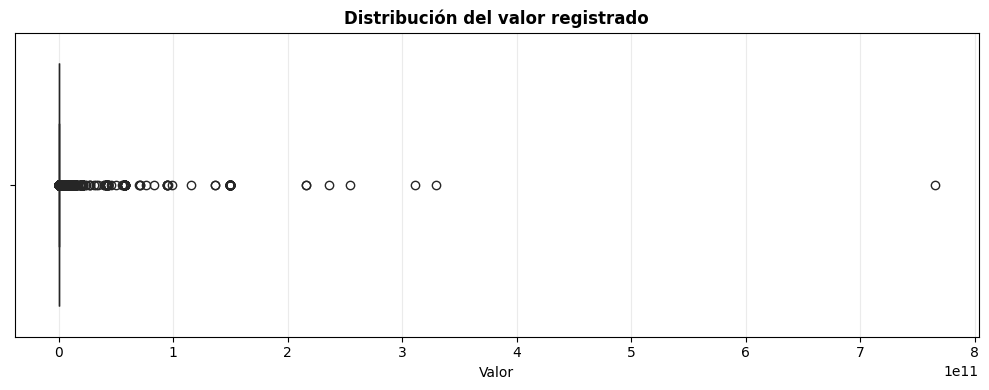

Registros con valor numérico: 278,954
Valores faltantes o no numéricos: 37,933


In [ ]:
# Copia de trabajo y conversión a numérico
valores = pd.to_numeric(
    df_compraventas_unicas["valor"],
    errors="coerce"
).dropna()

plt.figure(figsize=(10, 4))
sns.boxplot(x=valores, color="teal")

plt.title("Distribución del valor registrado")
plt.xlabel("Valor")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

print("Registros con valor numérico:", f"{len(valores):,}")
print("Valores faltantes o no numéricos:",
      f"{df_compraventas_unicas['valor'].shape[0] - len(valores):,}")


### Diagrama de barras y pie chart

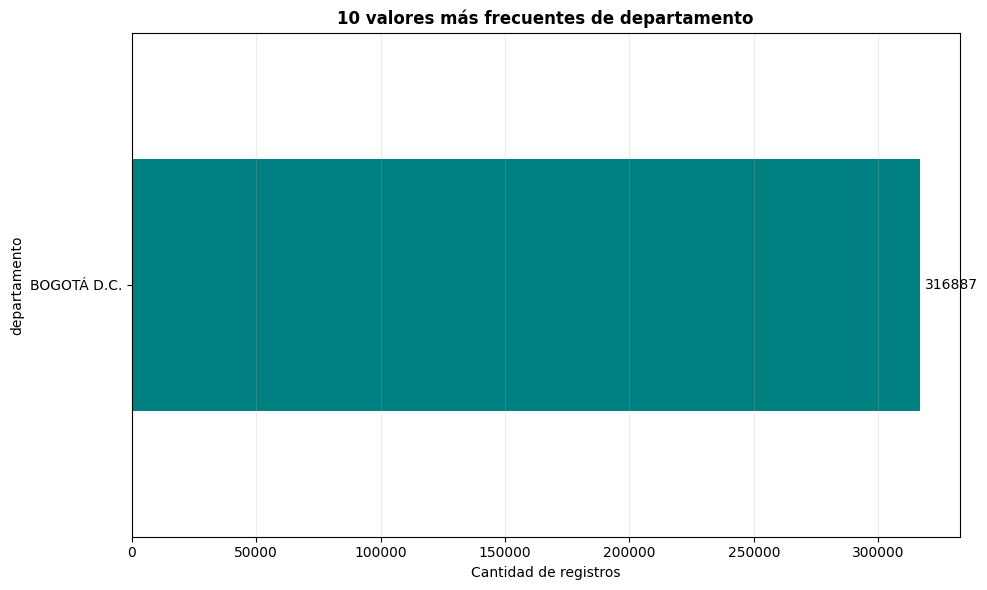

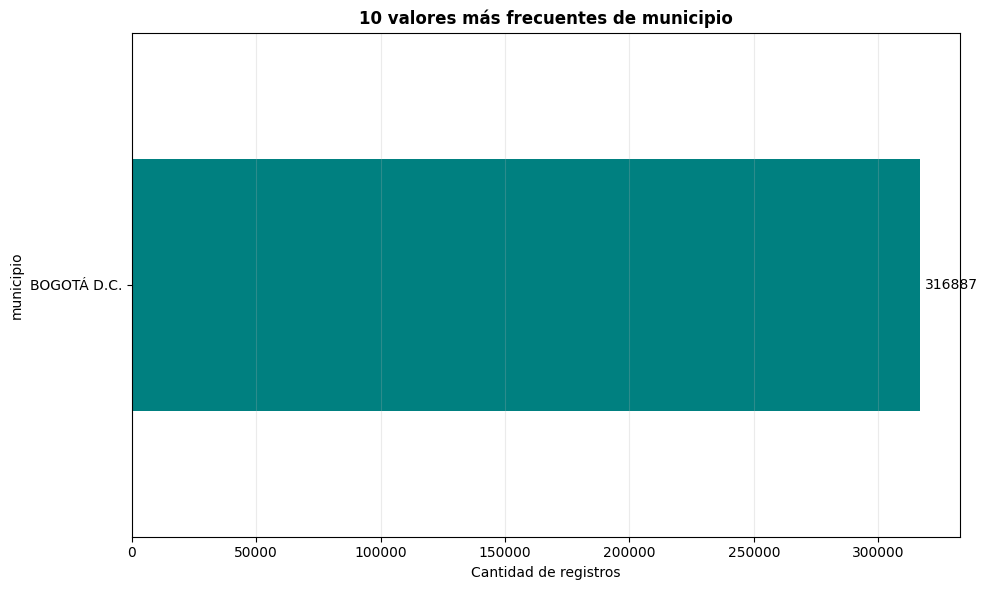

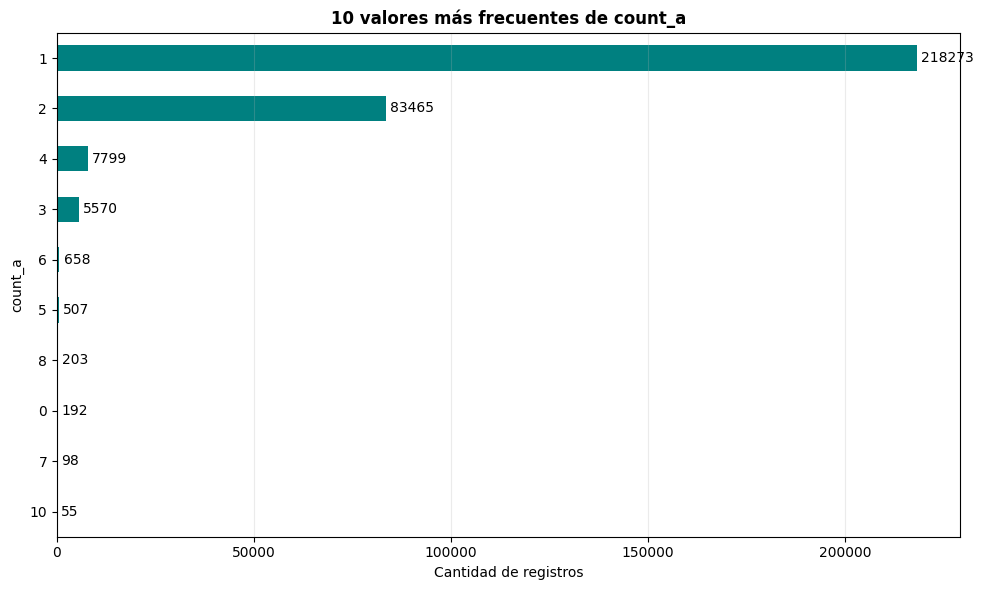

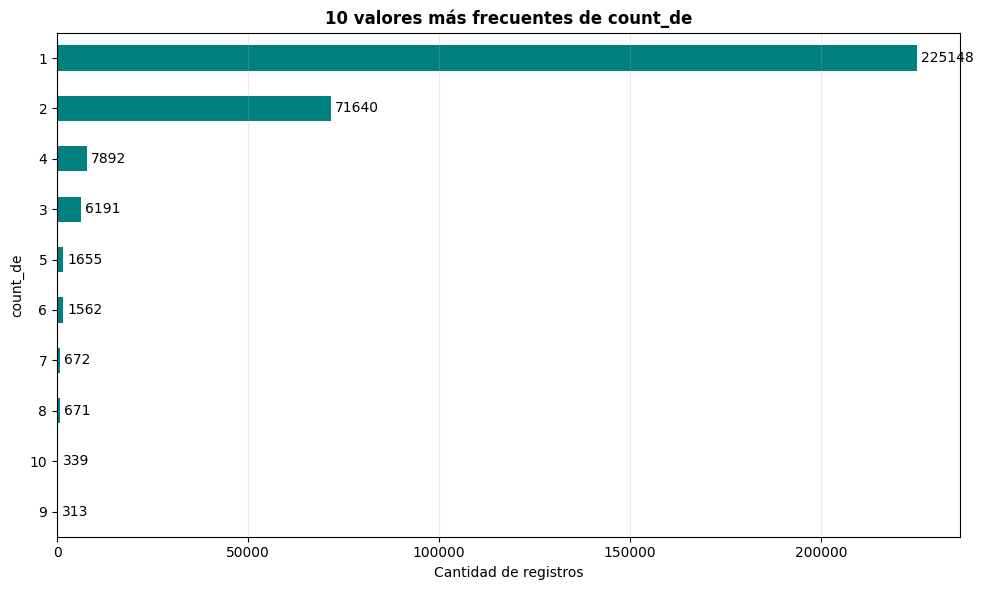

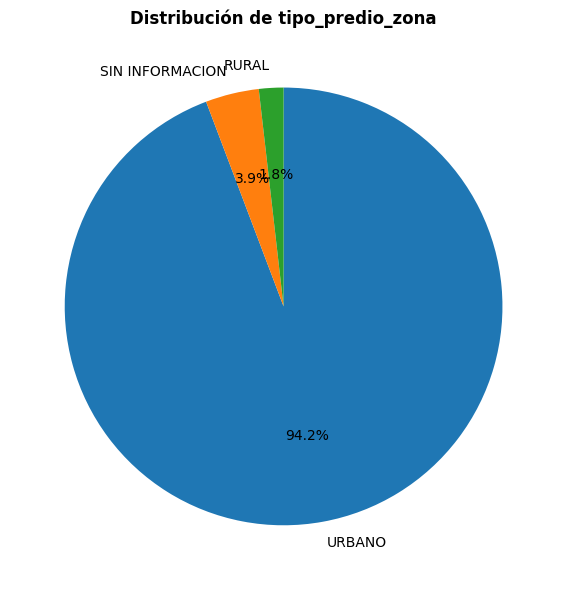

,cantidad,porcentaje
tipo_predio_zona,,
URBANO,298637,94.24
SIN INFORMACION,12507,3.95
RURAL,5743,1.81


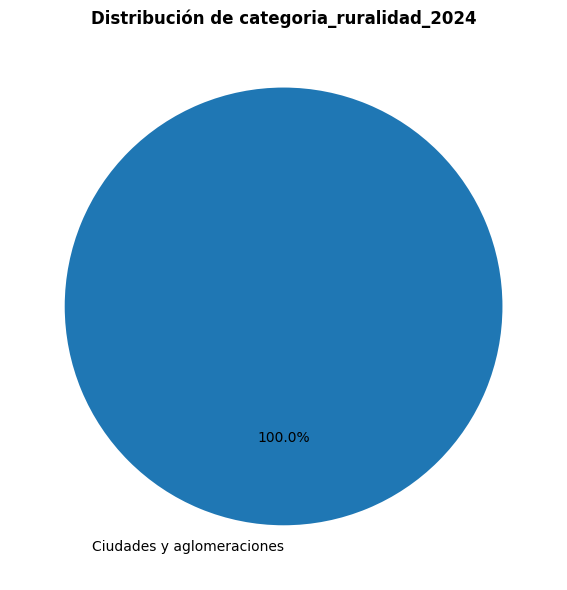

,cantidad,porcentaje
categoria_ruralidad_2024,,
Ciudades y aglomeraciones,316887,100.0


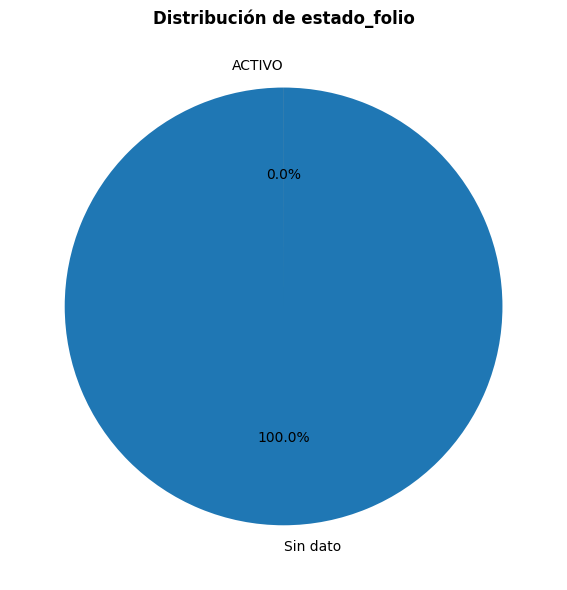

,cantidad,porcentaje
estado_folio,,
Sin dato,316877,100.0
ACTIVO,10,0.0


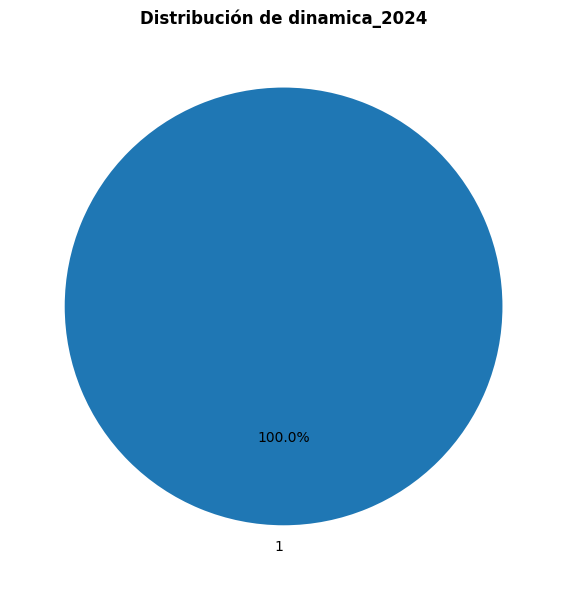

,cantidad,porcentaje
dinamica_2024,,
1,316887,100.0


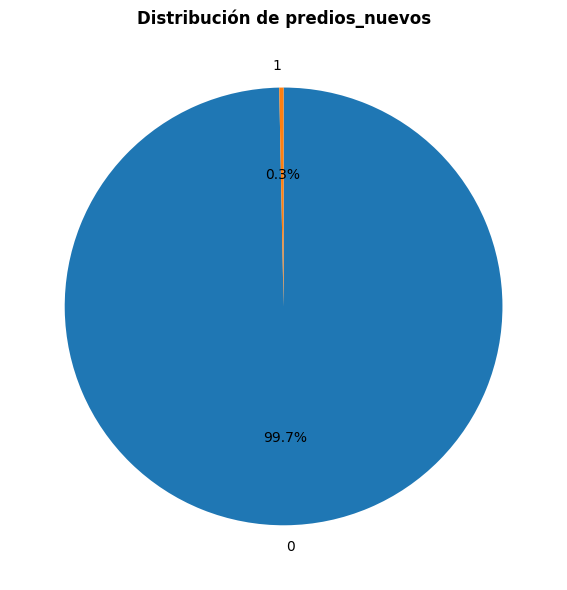

,cantidad,porcentaje
predios_nuevos,,
0,315879,99.68
1,1008,0.32


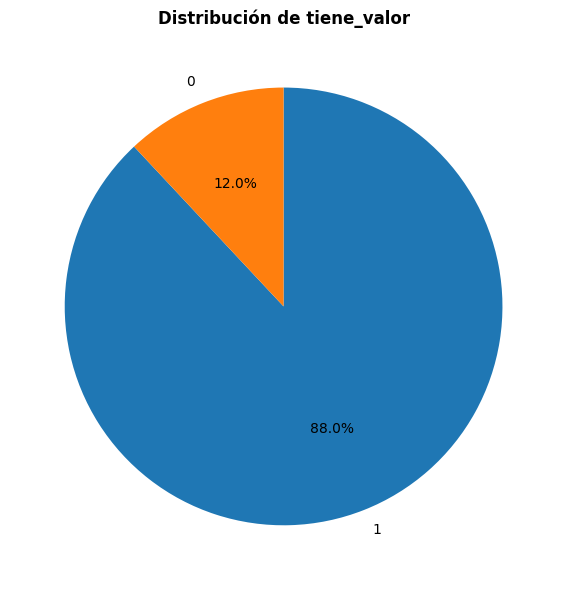

,cantidad,porcentaje
tiene_valor,,
1,278954,88.03
0,37933,11.97


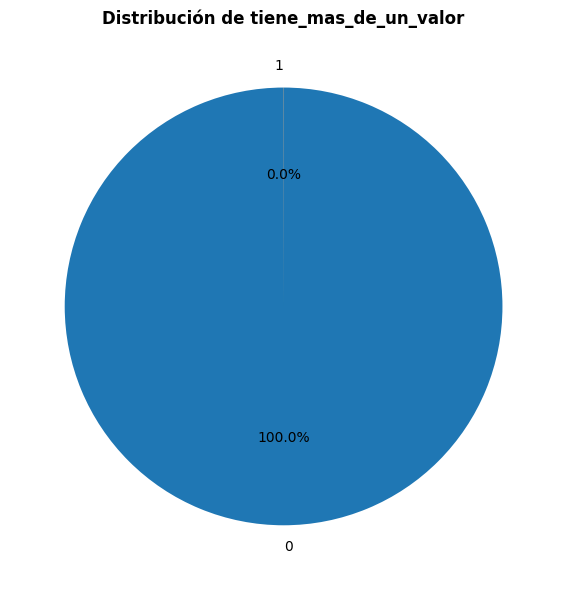

,cantidad,porcentaje
tiene_mas_de_un_valor,,
0,316850,99.99
1,37,0.01


In [ ]:
# Estilo básico
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"
COLOR = "teal"


def preparar_categorias(serie):
    """Convierte valores en etiquetas y representa nulos/vacíos como 'Sin dato'."""
    valores = serie.astype("string").str.strip()
    valores = valores.fillna("Sin dato")
    valores = valores.mask(valores.eq(""), "Sin dato")
    return valores


def graficar_top10(df, campo, titulo=None):
    """Grafica los 10 valores más frecuentes de una variable como barras horizontales."""
    if campo not in df.columns:
        print(f"No existe la columna: {campo}")
        return

    valores = preparar_categorias(df[campo])
    frecuencias = valores.value_counts().head(10).sort_values()

    if frecuencias.empty:
        print(f"No hay datos para graficar en {campo}")
        return

    ax = frecuencias.plot(kind="barh", color=COLOR)
    ax.set_title(titulo or f"10 valores más frecuentes de {campo}")
    ax.set_xlabel("Cantidad de registros")
    ax.set_ylabel(campo)
    ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()


def graficar_pastel(df, campo, max_categorias=8):
    """Grafica la distribución de una variable; agrupa las categorías restantes en 'Otros'."""
    if campo not in df.columns:
        print(f"No existe la columna: {campo}")
        return

    valores = preparar_categorias(df[campo])
    frecuencias = valores.value_counts()

    if frecuencias.empty:
        print(f"No hay datos para graficar en {campo}")
        return

    # Mantener las categorías principales y sumar el resto en "Otros"
    if len(frecuencias) > max_categorias:
        principales = frecuencias.head(max_categorias)
        otros = frecuencias.iloc[max_categorias:].sum()

        if otros > 0:
            frecuencias = pd.concat([
                principales,
                pd.Series({"Otros": otros})
            ])
        else:
            frecuencias = principales

    ax = frecuencias.plot(
        kind="pie",
        autopct="%1.1f%%",
        startangle=90,
        ylabel="",
        counterclock=False
    )

    ax.set_title(f"Distribución de {campo}")
    plt.tight_layout()
    plt.show()

    # Mostrar la tabla de frecuencias y porcentajes
    tabla = frecuencias.rename("cantidad").to_frame()
    tabla["porcentaje"] = (
        tabla["cantidad"] / tabla["cantidad"].sum() * 100
    ).round(2)

    display(tabla)


# Gráficas de barras: principales categorías
variables_barras = [
    "departamento",
    "municipio",
    "count_a",
    "count_de"
]

for campo in variables_barras:
    graficar_top10(df_compraventas_unicas, campo)


# Gráficas de pastel: variables categóricas y binarias
variables_pastel = [
    "tipo_predio_zona",
    "categoria_ruralidad_2024",
    "estado_folio",
    "dinamica_2024",
    "predios_nuevos",
    "tiene_valor",
    "tiene_mas_de_un_valor"
]

for campo in variables_pastel:
    graficar_pastel(df_compraventas_unicas, campo)


,cantidad_registros,valor_total,valor_mediano
year_radica,,,
2021,104471,21844738432914.0,183000000.0
2022,107368,42400432707208.0,184440000.0
2023,105048,38963979812585.398438,174000000.0


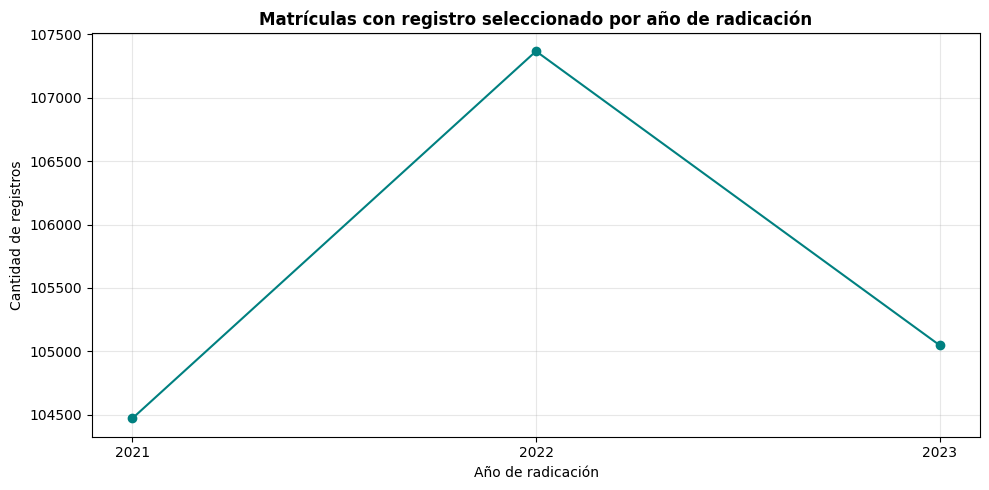

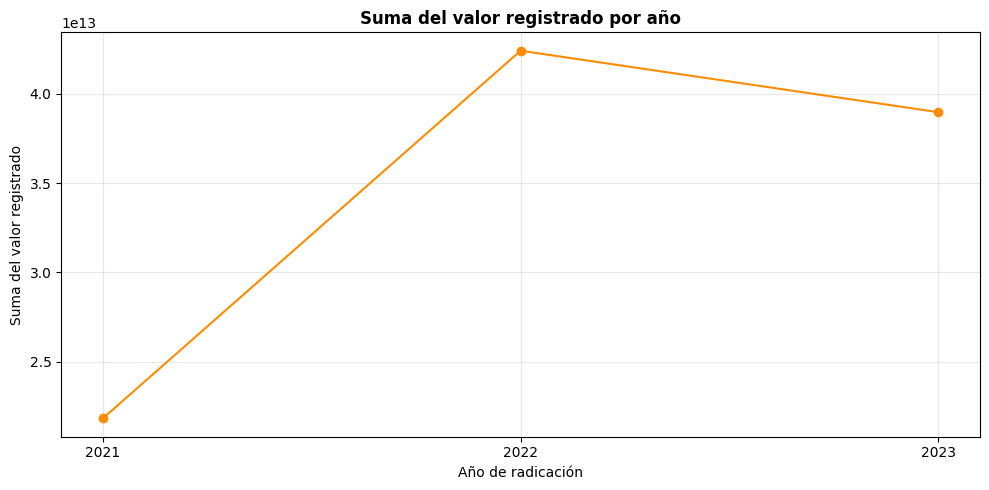

In [ ]:
# Copia de trabajo para no modificar el DataFrame original
df_tendencia = df_compraventas_unicas.copy()

# Asegurar formatos adecuados
df_tendencia["year_radica"] = pd.to_numeric(
    df_tendencia["year_radica"],
    errors="coerce"
)

df_tendencia["valor"] = pd.to_numeric(
    df_tendencia["valor"],
    errors="coerce"
)

# Excluir filas sin año para agrupar la tendencia
df_tendencia = df_tendencia.dropna(subset=["year_radica"]).copy()
df_tendencia["year_radica"] = df_tendencia["year_radica"].astype(int)

# Agrupar por año
tendencia = (
    df_tendencia
    .groupby("year_radica")
    .agg(
        cantidad_registros=("pk", "count"),
        valor_total=("valor", "sum"),
        valor_mediano=("valor", "median")
    )
    .sort_index()
)

display(tendencia)

# Gráfica 1: cantidad de matrículas/registros seleccionados por año
plt.figure(figsize=(10, 5))
plt.plot(
    tendencia.index,
    tendencia["cantidad_registros"],
    marker="o",
    color="teal"
)
plt.title("Matrículas con registro seleccionado por año de radicación")
plt.xlabel("Año de radicación")
plt.ylabel("Cantidad de registros")
plt.xticks(tendencia.index)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Gráfica 2: suma del valor registrado por año
plt.figure(figsize=(10, 5))
plt.plot(
    tendencia.index,
    tendencia["valor_total"],
    marker="o",
    color="darkorange"
)
plt.title("Suma del valor registrado por año")
plt.xlabel("Año de radicación")
plt.ylabel("Suma del valor registrado")
plt.xticks(tendencia.index)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Conclusión
- Una vez realizado la limpieza podemos ver que fecha_radica_texto tiene datos desde 2021-01-04 hasta el 2023-12-29 y fecha_apertura_texto tiene datos desde 1900-01-01 hasta 2024-03-05.
- valor identifica que va desde 0 hasta 765062020000
- Se realiza un boxplot para valores donde se ve que está muy sesgada hacia la derecha donde la mayoría de los valores se concentran cerca de 0. Auqnue también en la descripción de valor se puede ver que como promedio estaría en 369986273 y uno de los que se encuentra en 25% como 12000000 por lo que si tener en cuenta este tipo de casos
- En distribución de tipo_predio_zona al ser una ciudad ya toma el 94% el area urbano. Rural representa tan solo un 1.80% lo cual no es nada y SIN INFORMACIÓN en 3.95% que podrían ser considerados una opción para eliminar esos valores para Bogotá.
- Para Predios_nuevos en 99.68% está en 0, esto significa que no es un nuevo predio donde no ha surgido un nuevo folio y esto es porque se decir usar la matrícula de aquellos últimos registros
- Por último en tendencia, se puede ver la cantidad de transacciones que ha habido en Bogotá desde el año 2021 - 2023 donde hay un pico en 2022 superando la gran cantidad de transacciones realizado ese año. También se mira con valor que estaría entre 2022 y 2023 que el valor es estable pero que si hubo un aumento notable desde el 2021 - 2022